# Paper 2 · Cosmos-Predict2 — extended eval (section 7 onward)

Standalone: only needs `cosmos_outputs.zip` (no training, no inference). Sections 7-8 are the original code; the rest adds:
- extra metrics: Latent L2 (Wan2.1-VAE), FVD, LPIPS, I3D-L2 (per-video FVD proxy)
- 8 tables + 10 figures, each with a short auto-generated comment
- comparison videos for all 8 held-out videos

GPU recommended for LPIPS / Latent L2 / FVD, the rest runs on CPU. If a metric fails the cell just warns and later cells skip it.

## 0 · Setup (unzip `cosmos_outputs.zip`)

In [1]:
#@title 0 · Setup: unzip cosmos_outputs.zip (no training / inference needed)
# setup env, paths, unzip
import os, sys, json, glob, shutil, zipfile, pathlib, subprocess, warnings
warnings.filterwarnings("ignore")

# pip helper, doesn't stop on failure
def pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
# libs for eval
pip("scikit-image", "opencv-python-headless", "imageio", "imageio-ffmpeg", "pandas", "matplotlib", "seaborn", "scipy", "pillow")

# same var names / paths as the original notebook
ROOT = pathlib.Path("/content/cosmos-predict2")
RES  = pathlib.Path("/content/eyecode-official/results")
GT   = ROOT / "datasets/eyecode_gr1_eval/videos"
ZIP_PATH = "/content/cosmos_outputs.zip"  # change if zip is elsewhere

# data ready?
def _ready():
    return GT.is_dir() and (ROOT / "output/eval/base").is_dir() and (ROOT / "output/eval/lora").is_dir() and RES.is_dir()

# only unzip if data missing
if not _ready():
    if not os.path.exists(ZIP_PATH):
        from google.colab import files
        print("Hãy upload cosmos_outputs.zip"); up = files.upload()
        src = os.path.abspath(next(iter(up)))
        if src != ZIP_PATH: shutil.move(src, ZIP_PATH)
    # unzip to tmp, then copy over
    tmp = pathlib.Path("/content/_unzip"); shutil.rmtree(tmp, ignore_errors=True)
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(tmp)
    ROOT.mkdir(parents=True, exist_ok=True); RES.mkdir(parents=True, exist_ok=True)
    for sub in ("datasets", "output"):
        shutil.copytree(tmp / sub, ROOT / sub, dirs_exist_ok=True)
    shutil.copytree(tmp / "content/eyecode-official/results", RES, dirs_exist_ok=True)
    shutil.rmtree(tmp, ignore_errors=True)
# fail if still missing
assert _ready(), "Không tìm thấy dữ liệu - kiểm tra lại cosmos_outputs.zip"

# gpu info
try:
    import torch; NGPU = torch.cuda.device_count()
    print("GPU:", torch.cuda.get_device_name(0) if NGPU else "không có (Latent L2 / LPIPS / FVD sẽ chạy rất chậm hoặc bị bỏ qua)")
except Exception:
    NGPU = 0; print("Không import được torch")
# expect 8 / 8 / 8
print("GT videos      :", len(list(GT.glob('*.mp4'))))
print("base / lora    :", len(list((ROOT/'output/eval/base').glob('*.mp4'))), "/", len(list((ROOT/'output/eval/lora').glob('*.mp4'))))
print("results (zip)  :", sorted(p.name for p in RES.iterdir()))

Hãy upload cosmos_outputs.zip


Saving cosmos_outputs.zip to cosmos_outputs.zip
GPU: NVIDIA A100-SXM4-40GB
GT videos      : 8
base / lora    : 8 / 8
results (zip)  : ['compare_64.mp4', 'compare_9.mp4', 'qualitative_best_worst.png', 'summary.md', 'train.log', 'video_metrics_scatter.png', 'video_scores_base.json', 'video_scores_lora.json', 'video_summary.json']


In [9]:
# unzip helper package (only if you uploaded eyecode-official.zip)
!unzip /content/eyecode-official.zip -d /content/eyecode-official

Archive:  /content/eyecode-official.zip
  inflating: /content/eyecode-official/eyecode-official/overlay/eyecode_gr1_lora_small.py  
  inflating: /content/eyecode-official/eyecode-official/README.md  
  inflating: /content/eyecode-official/eyecode-official/notebooks/02_gr00t_dreams_dreamgen.ipynb  
  inflating: /content/eyecode-official/eyecode-official/notebooks/01_cosmos_predict2.ipynb  
 extracting: /content/eyecode-official/eyecode-official/tests/__init__.py  
  inflating: /content/eyecode-official/eyecode-official/tests/test_glue.py  
  inflating: /content/eyecode-official/eyecode-official/eyecode/report.py  
  inflating: /content/eyecode-official/eyecode-official/eyecode/idm_eval.py  
  inflating: /content/eyecode-official/eyecode-official/eyecode/__init__.py  
  inflating: /content/eyecode-official/eyecode-official/eyecode/video_metrics.py  
  inflating: /content/eyecode-official/eyecode-official/eyecode/prepare_subset.py  
  inflating: /content/eyecode-official/eyecode-official/

In [10]:
import types, dataclasses
import numpy as np, cv2
sys.path.insert(0, "/content/eyecode-official")
# use original package if it exists
try:
    from eyecode import video_metrics as _vm_probe, report as _rp_probe
    print("✓ dùng package eyecode gốc")
except Exception:
    # else rebuild same-named functions
    from PIL import Image
    import imageio.v2 as iio

    # per-video scores container
    @dataclasses.dataclass
    class VideoScore:
        name: str; psnr: float; ssim: float; frames: int; psnr_by_frame: list

    # read video -> RGB array
    def read_video(path, max_frames=None):
        cap = cv2.VideoCapture(str(path)); fr = []
        while max_frames is None or len(fr) < max_frames:
            ok, f = cap.read()
            if not ok: break
            fr.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        cap.release()
        return np.stack(fr)

    def load_scores(path):
        return [VideoScore(**d) for d in json.loads(pathlib.Path(path).read_text())]

    def save_scores(scores, path):
        pathlib.Path(path).write_text(json.dumps([dataclasses.asdict(s) for s in scores], indent=1))

    # PSNR/SSIM vs GT, reuse cached scores if present
    def evaluate_run(gt_dir, run_dir):
        run = pathlib.Path(run_dir).name
        cache = RES / f"video_scores_{run}.json"
        if cache.exists():  # cached scores
            return load_scores(cache)
        from skimage.metrics import structural_similarity as ssim_fn
        out = []
        for p in sorted(pathlib.Path(run_dir).glob("*.mp4")):
            gen = read_video(p); H, W = gen.shape[1:3]
            gt = read_video(pathlib.Path(gt_dir) / p.name, max_frames=len(gen))
            gt = np.stack([np.array(Image.fromarray(f).resize((W, H), Image.LANCZOS)) for f in gt])
            T = min(len(gt), len(gen)); ps, ss = [], []
            for k in range(1, T):  # skip conditioning frame
                mse = np.mean((gt[k].astype(np.float64) - gen[k].astype(np.float64)) ** 2)
                ps.append(float(10 * np.log10(255 ** 2 / max(mse, 1e-10))))
                g = lambda x: cv2.cvtColor(x, cv2.COLOR_RGB2GRAY)
                ss.append(float(ssim_fn(g(gt[k]), g(gen[k]), data_range=255)))
            out.append(VideoScore(p.name, float(np.mean(ps)), float(np.mean(ss)), T - 1, ps))
        return out

    # stack videos side by side with labels
    def side_by_side(paths, labels, out, fps=16):
        vids = [read_video(p, max_frames=93) for p in paths]
        T = min(len(v) for v in vids); H, W = vids[-1].shape[1:3]
        w = iio.get_writer(str(out), fps=fps, codec="libx264", pixelformat="yuv420p", macro_block_size=1, ffmpeg_params=["-crf", "23"])
        for t in range(T):
            panels = []
            for v, lab in zip(vids, labels):
                f = cv2.resize(v[t], (W, H), interpolation=cv2.INTER_AREA).copy()
                cv2.rectangle(f, (0, 0), (190, 34), (0, 0, 0), -1)
                cv2.putText(f, lab, (8, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
                panels.append(f)
            w.append_data(np.hstack(panels))
        w.close()

    # summary table + paired test
    def video_section(res_dir, runs):
        res_dir = pathlib.Path(res_dir)
        sc = {r: load_scores(res_dir / f"video_scores_{r}.json") for r in runs}
        lines = ["| run | n | PSNR (dB) | SSIM |", "|---|---|---|---|"]; summ = {}
        for r in runs:
            p = np.array([s.psnr for s in sc[r]]); q = np.array([s.ssim for s in sc[r]])
            lines.append(f"| {r} | {len(p)} | {p.mean():.2f} ± {p.std(ddof=1):.2f} | {q.mean():.3f} ± {q.std(ddof=1):.3f} |")
            summ[r] = dict(n=len(p), psnr_mean=float(p.mean()), psnr_std=float(p.std(ddof=1)), ssim_mean=float(q.mean()), ssim_std=float(q.std(ddof=1)))
        if len(runs) == 2:
            a, b = runs
            cached = res_dir / "video_summary.json"
            cs = json.loads(cached.read_text()) if cached.exists() else {}
            for met in ("psnr", "ssim"):
                key = f"paired_{met}"
                if key in cs: st = cs[key]
                else:
                    x = np.array([getattr(s, met) for s in sc[b]]) - np.array([getattr(s, met) for s in sc[a]])
                    bs = x[np.random.default_rng(0).integers(0, len(x), (10000, len(x)))].mean(1)
                    st = dict(metric=met, n=len(x), mean_diff=float(x.mean()), ci95=[float(v) for v in np.percentile(bs, [2.5, 97.5])], win_rate=float((x > 0).mean()))
                summ[key] = st
                lines += ["", f"Paired {b} − {a} ({met.upper()}): mean {st['mean_diff']:+.4f}, 95% bootstrap CI [{st['ci95'][0]:+.4f}, {st['ci95'][1]:+.4f}], {b} better on {st['win_rate']:.0%} of {st['n']} videos"]
        return lines, summ

    # pack into fake `eyecode` module
    _vm = types.ModuleType("eyecode.video_metrics")
    for _f in (VideoScore, read_video, load_scores, save_scores, evaluate_run, side_by_side):
        setattr(_vm, _f.__name__, _f)
    _rp = types.ModuleType("eyecode.report"); _rp.video_section = video_section
    _pk = types.ModuleType("eyecode"); _pk.video_metrics = _vm; _pk.report = _rp; _pk.__path__ = []
    sys.modules.update({"eyecode": _pk, "eyecode.video_metrics": _vm, "eyecode.report": _rp})
    print("✓ package eyecode gốc không có -> dùng bản tương thích (đọc lại điểm đã lưu trong video_scores_*.json)")

✓ dùng package eyecode gốc


## 1 · Quantitative evaluation: generated vs ground-truth video (held-out episodes)

In [11]:
from eyecode import video_metrics as vm, report
RES = pathlib.Path("/content/eyecode-official/results"); RES.mkdir(exist_ok=True)
GT = ROOT / "datasets/eyecode_gr1_eval/videos"
# PSNR/SSIM vs GT for each run
for run in ("base", "lora"):
    vm.save_scores(vm.evaluate_run(GT, ROOT / f"output/eval/{run}"), RES / f"video_scores_{run}.json")
# base vs lora table
lines, summ = report.video_section(RES, ["base", "lora"])
print("\n".join(lines))

| run | n | PSNR (dB) | SSIM |
|---|---|---|---|
| base | 8 | 12.08 ± 1.11 | 0.443 ± 0.055 |
| lora | 8 | 12.08 ± 1.15 | 0.445 ± 0.056 |

Paired lora − base (PSNR): mean +0.0004, 95% bootstrap CI [-0.0764, +0.0821], lora better on 38% of 8 videos

Paired lora − base (SSIM): mean +0.0014, 95% bootstrap CI [-0.0001, +0.0029], lora better on 75% of 8 videos


## 2 · Representative outputs, success and failure cases (computed from the scores, not hand-written)

largest LoRA gain : [('9.mp4', 0.21), ('65.mp4', 0.16)]
largest LoRA loss : [('64.mp4', -0.14), ('19.mp4', -0.1)]
base: PSNR first 10 frames 13.98 dB -> last 10 frames 11.41 dB (drift 2.57 dB)
lora: PSNR first 10 frames 13.98 dB -> last 10 frames 11.32 dB (drift 2.66 dB)


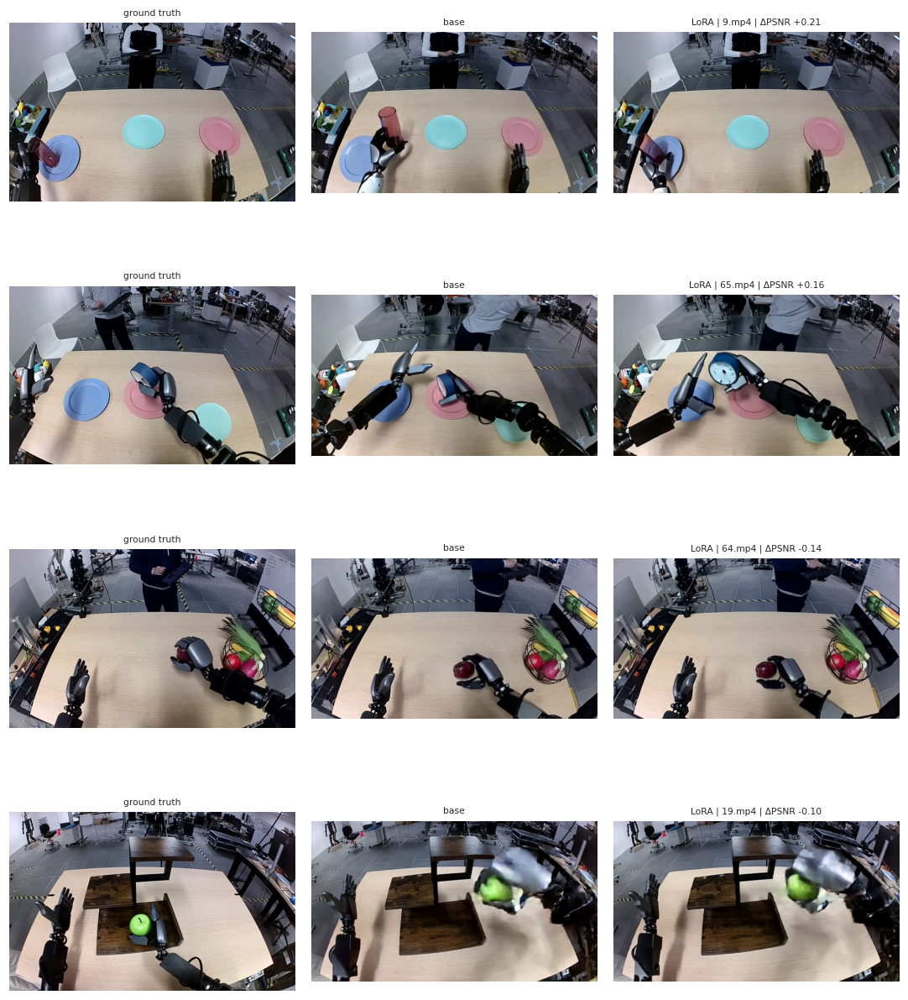

In [13]:
import numpy as np, matplotlib.pyplot as plt, IPython.display as ipd
base, lora = (vm.load_scores(RES / f"video_scores_{r}.json") for r in ("base", "lora"))
b = {s.name: s for s in base}; l = {s.name: s for s in lora}
# delta = lora PSNR - base PSNR
names = sorted(set(b) & set(l)); delta = {n: l[n].psnr - b[n].psnr for n in names}
order = sorted(names, key=delta.get)
# best / worst 2 videos
worst, best = order[:2], order[-2:][::-1]
print("largest LoRA gain :", [(n, round(delta[n], 2)) for n in best])
print("largest LoRA loss :", [(n, round(delta[n], 2)) for n in worst])
# error growth with time: PSNR per frame averaged over videos
# common #frames
T = min(len(b[n].psnr_by_frame) for n in names)
# avg PSNR per frame, drift = first 10 - last 10
for run, d in (("base", b), ("lora", l)):
    pf = np.mean([d[n].psnr_by_frame[:T] for n in names], axis=0)
    print(f"{run}: PSNR first 10 frames {pf[:10].mean():.2f} dB -> last 10 frames {pf[-10:].mean():.2f} dB (drift {pf[:10].mean()-pf[-10:].mean():.2f} dB)")
# grid: GT | base | LoRA (mid frame)
fig, ax = plt.subplots(len(best + worst), 3, figsize=(10, 3 * len(best + worst)))
for r, n in enumerate(best + worst):
    for c, (lab, p) in enumerate((("ground truth", GT / n), ("base", ROOT / f"output/eval/base/{n}"), ("LoRA", ROOT / f"output/eval/lora/{n}"))):
        v = vm.read_video(p); ax[r, c].imshow(v[len(v) // 2 if c == 0 else min(len(v), 93) // 2]); ax[r, c].axis("off")
        ax[r, c].set_title(f"{lab} | {n[:22]} | ΔPSNR {delta[n]:+.2f}" if c == 2 else lab, fontsize=7)
fig.tight_layout(); fig.savefig(RES / "qualitative_best_worst.png", dpi=150); plt.show()
# side-by-side for best + worst
for n in best[:1] + worst[:1]:
    vm.side_by_side([GT / n, ROOT / f"output/eval/base/{n}", ROOT / f"output/eval/lora/{n}"], ["ground truth", "base", "LoRA"], RES / f"compare_{n}")
    ipd.display(ipd.Video(str(RES / f"compare_{n}"), embed=True, width=900))

## 3 · Eval: 8 videos × (Base, LoRA)

| Metric | Measures | Better | How |
|---|---|---|---|
| PSNR, SSIM | pixel / structure diff vs GT | higher | reused from section 7 (`video_scores_*.json`) |
| LPIPS | perceptual diff (AlexNet) | lower | frame average, conditioning frame skipped |
| Latent L2 | RMSE in Wan2.1-VAE latent space (normalized) | lower | latent frame 0 skipped |
| FVD | Fréchet distance between clip feature distributions | lower | 16-frame clips, stride 4; I3D if it downloads, else R3D-18 |
| I3D-L2 | per-video clip feature distance | lower | mean ‖f_gen − f_GT‖ over matching clips |

Alignment as in section 7: by frame index, frame 0 dropped, GT (1280×800) resized to 768×432 (Lanczos).

Notes: only 8 videos, so read results through the CIs. FVD on so few samples is only good for relative Base vs LoRA.

In [14]:
# Shared helpers: aligned video loading, paired stats, cache
# shared vars/functions for 9b-9f, run first
import re, math, time, pickle, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, cv2
from PIL import Image
from scipy import stats as sps
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})
# colors
COL = {"base": "#5B7DB1", "lora": "#E8833A", "good": "#2E9E5B", "bad": "#D1495B", "gt": "#4D4D4D"}
# runs to compare
RUNS = ("base", "lora"); LAB = {"base": "Base", "lora": "LoRA"}
# video names (sorted by id)
NAMES = sorted((p.name for p in GT.glob("*.mp4")), key=lambda s: int(s[:-4]))  # 9, 19, 60, 62, 64, 65, 98, 100
VID = [n[:-4] for n in NAMES]
# gpu if available
try:
    import torch; DEV = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    DEV = "cpu"

# alignment like section 7: by frame idx, drop frame 0, resize GT (Lanczos)
# read video -> RGB
def read_rgb(path, max_frames=None):
    cap = cv2.VideoCapture(str(path)); fr = []
    while max_frames is None or len(fr) < max_frames:
        ok, f = cap.read()
        if not ok: break
        fr.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    cap.release(); return np.stack(fr)

# cache
_AL = {}
# load GT/base/lora, same #frames, GT resized
def load_aligned(name, T=93):
    if name in _AL: return _AL[name]
    b = read_rgb(ROOT / f"output/eval/base/{name}"); l = read_rgb(ROOT / f"output/eval/lora/{name}")
    T = min(T, len(b), len(l)); H, W = b.shape[1:3]
    g = read_rgb(GT / name, T)
    g = np.stack([np.array(Image.fromarray(f).resize((W, H), Image.LANCZOS)) for f in g])
    _AL.clear(); _AL[name] = (g[:T], b[:T], l[:T]); return _AL[name]

# saved PSNR/SSIM from section 7
SC = {r: {d["name"]: d for d in json.loads((RES / f"video_scores_{r}.json").read_text())} for r in RUNS}

# metrics: (label, higher is better, format)
METRICS = {
    "psnr":      ("PSNR (dB)", True,  "{:.3f}"),
    "ssim":      ("SSIM",      True,  "{:.4f}"),
    "lpips":     ("LPIPS",     False, "{:.4f}"),
    "latent_l2": ("Latent L2", False, "{:.4f}"),
    "feat_l2":   ("I3D-L2",    False, "{:.3f}"),
}

# result cache
EXT_PATH = RES / "ext_metrics_cache.pkl"
EXT = pickle.load(open(EXT_PATH, "rb")) if EXT_PATH.exists() else {}
def ext_save(): pickle.dump(EXT, open(EXT_PATH, "wb"))
def ext_has(group, run, name): return name in EXT.get(group, {}).get(run, {})
def ext_put(group, run, name, val): EXT.setdefault(group, {}).setdefault(run, {})[name] = val

# paired stats
def paired_stats(base, lora, higher_better, n_boot=10000, seed=0):
    b, l = np.asarray(base, float), np.asarray(lora, float)
    # d = lora - base, imp = positive when lora better
    d = l - b; imp = d if higher_better else -d; n = len(d)
    # bootstrap 95% CI
    boots = d[np.random.default_rng(seed).integers(0, n, (n_boot, n))].mean(1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    try: pw = float(sps.wilcoxon(d).pvalue)
    except ValueError: pw = 1.0
    sd = float(d.std(ddof=1))
    pt = float(sps.ttest_rel(l, b).pvalue) if sd > 0 else 1.0
    return dict(n=n, base=float(b.mean()), lora=float(l.mean()), diff=float(d.mean()), lo=float(lo), hi=float(hi),
                rel=float(100 * d.mean() / abs(b.mean())), win=int((imp > 0).sum()), loss=int((imp < 0).sum()),
                p_w=pw, p_t=pt, dz=float(imp.mean() / sd) if sd > 0 else 0.0, sd=sd,
                half=float(sps.t.ppf(0.975, n - 1) * sd / np.sqrt(n)), sd_between=float(b.std(ddof=1)))

# verdict text from stats
def verdict(st, hb):
    ci0 = st["lo"] > 0 or st["hi"] < 0  # CI excludes 0
    who = "LoRA" if (st["diff"] > 0) == hb else "Base"
    if ci0 and st["p_w"] < 0.05: tag = f"{who} tốt hơn (có ý nghĩa thống kê)"
    elif ci0 or st["p_w"] < 0.10: tag = f"nghiêng về {who} (chưa chắc chắn)"
    else: return "không có khác biệt rõ rệt"
    return tag + (" nhưng biên độ rất nhỏ (<1%)" if abs(st["rel"]) < 1.0 else "")

# p-value format
def fmt_p(p): return "<0.001" if p < 0.001 else f"{p:.3f}"

# report export
REPORT = []
# say: show md + add to REPORT
def say(md):
    display(Markdown(md)); REPORT.append(md)

# df -> markdown
def df_md(df, fmt="{:.4f}"):
    d = df.copy()
    if isinstance(d.columns, pd.MultiIndex): d.columns = [" · ".join(map(str, c)) for c in d.columns]
    d = d.reset_index()
    rows = ["| " + " | ".join(("–" if np.isnan(v) else fmt.format(v)) if isinstance(v, (float, np.floating)) else str(v) for v in r) + " |" for r in d.itertuples(index=False)]
    return "\n".join(["| " + " | ".join(map(str, d.columns)) + " |", "|" + "---|" * len(d.columns)] + rows)

# show_table: csv + report + display
def show_table(T, fname, title, styler=None, fmt="{:.4f}"):
    T.to_csv(RES / f"{fname}.csv")
    REPORT.append(f"### {title}\n\n" + df_md(T, fmt))
    try: display(styler(T) if styler else T.style.format(fmt))
    except Exception: display(T)

# show_fig: png + report + show
def show_fig(fig, fname, title=None):
    fig.tight_layout(); fig.savefig(RES / fname, dpi=150, bbox_inches="tight"); plt.show(); plt.close(fig)
    REPORT.append(f"### {title or fname}\n\n![{fname}]({fname})")
print("OK · video:", VID, "· thiết bị:", DEV)

OK · video: ['9', '19', '60', '62', '64', '65', '98', '100'] · thiết bị: cuda


### Extra metrics (cached, reruns skip finished parts)

In [15]:
#@title 9b · (CPU) per-frame SSIM + Base vs LoRA difference
# SSIM* per frame, only for time curves (main SSIM = section 7)
from skimage.metrics import structural_similarity as _ssim
# to gray
_gray = lambda x: cv2.cvtColor(x, cv2.COLOR_RGB2GRAY)
# per-frame PSNR
def _psnr_frames(a, b):
    return np.array([10 * np.log10(255.0 ** 2 / max(np.mean((x.astype(np.float32) - y.astype(np.float32)) ** 2), 1e-10)) for x, y in zip(a, b)])
t0 = time.time()
for n in NAMES:
    # skip if cached
    if n in EXT.get("bl", {}) and all(ext_has("ssim_frame", r, n) for r in RUNS): continue
    gt, b, l = load_aligned(n)
    # skip frame 0
    for r, g in (("base", b), ("lora", l)):
        ext_put("ssim_frame", r, n, np.array([_ssim(_gray(gt[k]), _gray(g[k]), data_range=255, gaussian_weights=True, sigma=1.5, use_sample_covariance=False) for k in range(1, len(g))]))
    # base vs lora diff (PSNR per frame, MAE)
    EXT.setdefault("bl", {})[n] = dict(psnr_frame=_psnr_frames(b[1:], l[1:]), mae=float(np.abs(b[1:].astype(np.int16) - l[1:].astype(np.int16)).mean()))
    print(f"  {n:8s} xong  ({time.time() - t0:.0f}s)")
ext_save(); print("✓ SSIM* theo frame + độ khác biệt base↔LoRA")

✓ SSIM* theo frame + độ khác biệt base↔LoRA


In [16]:
#@title 9c · (GPU) LPIPS vs ground truth (AlexNet)
# try/except, only warns on failure
try:
    # skip if cached
    if not all(ext_has("lpips_frame", r, n) for r in RUNS for n in NAMES):
        pip("lpips")
        import torch, lpips
        # model
        _lp = lpips.LPIPS(net="alex", verbose=False).to(DEV).eval()
        # uint8 (T,H,W,3) -> [-1,1] (T,3,H,W)
        _t = lambda x: torch.from_numpy(x).to(DEV).permute(0, 3, 1, 2).float() / 127.5 - 1
        for n in NAMES:
            if all(ext_has("lpips_frame", r, n) for r in RUNS): continue
            gt, b, l = load_aligned(n)
            # batches of 8 frames
            for r, g in (("base", b), ("lora", l)):
                out = []
                for i in range(1, len(g), 8):  # skip frame 0
                    with torch.no_grad(): out.append(_lp(_t(gt[i:i + 8]), _t(g[i:i + 8])).flatten().cpu().numpy())
                ext_put("lpips_frame", r, n, np.concatenate(out))
            print("  LPIPS", n)
        ext_save(); del _lp
    print("✓ LPIPS")
except Exception as e:
    print("⚠️ Bỏ qua LPIPS:", type(e).__name__, e)

✓ LPIPS


In [17]:
#@title 9d · (GPU) Latent L2 in Wan2.1-VAE latent space (Cosmos-Predict2 tokenizer)
# encode GT/base/LoRA -> normalized latent -> RMSE vs GT
# latent frame 0 (conditioning) dropped
# try/except, only warns on failure
try:
    import torch
    if not all(ext_has("latent_frame", r, n) for r in RUNS for n in NAMES):
        # load VAE (install diffusers if missing)
        try: from diffusers import AutoencoderKLWan
        except ImportError:
            pip("-U", "diffusers>=0.33", "transformers", "accelerate"); from diffusers import AutoencoderKLWan
        vae = AutoencoderKLWan.from_pretrained("Wan-AI/Wan2.1-T2V-1.3B-Diffusers", subfolder="vae", torch_dtype=torch.float32).to(DEV).eval()
        # latent norm stats
        _mu = torch.tensor(vae.config.latents_mean, device=DEV).view(1, -1, 1, 1, 1)
        _sd = torch.tensor(vae.config.latents_std, device=DEV).view(1, -1, 1, 1, 1)

        @torch.no_grad()
        def encode_latent(frames):  # (T,H,W,3) uint8 -> (C,t,h,w)
            frames = frames[: (len(frames) - 1) // 4 * 4 + 1]  # VAE needs T = 4k+1 (93 -> 24 latent frames)
            x = torch.from_numpy(frames).to(DEV).float().permute(3, 0, 1, 2).unsqueeze(0) / 127.5 - 1
            z = vae.encode(x).latent_dist.mean
            return ((z - _mu) / _sd)[0].float().cpu()

        for n in NAMES:
            if all(ext_has("latent_frame", r, n) for r in RUNS): continue
            gt, b, l = load_aligned(n)
            zg, zb, zl = encode_latent(gt), encode_latent(b), encode_latent(l)
            for r, z in (("base", zb), ("lora", zl)):
                ext_put("latent_frame", r, n, (z[:, 1:] - zg[:, 1:]).pow(2).mean(dim=(0, 2, 3)).sqrt().numpy())  # RMSE per latent frame
            EXT.setdefault("bl_latent", {})[n] = float((zb[:, 1:] - zl[:, 1:]).pow(2).mean().sqrt())  # base<->LoRA distance
            print("  Latent", n, "· latent shape", tuple(zg.shape))
        ext_save(); del vae
        if DEV == "cuda": torch.cuda.empty_cache()
    print("✓ Latent L2")
except Exception as e:
    print("⚠️ Bỏ qua Latent L2:", type(e).__name__, e)

  Latent 9.mp4 · latent shape (16, 24, 54, 96)
  Latent 19.mp4 · latent shape (16, 24, 54, 96)
  Latent 60.mp4 · latent shape (16, 24, 54, 96)
  Latent 62.mp4 · latent shape (16, 24, 54, 96)
  Latent 64.mp4 · latent shape (16, 24, 54, 96)
  Latent 65.mp4 · latent shape (16, 24, 54, 96)
  Latent 98.mp4 · latent shape (16, 24, 54, 96)
  Latent 100.mp4 · latent shape (16, 24, 54, 96)
✓ Latent L2


In [18]:
#@title 9e · (GPU) Clip features for FVD (I3D, fallback R3D-18)
# 16-frame clips, stride 4, frame 0 dropped -> ~20 clips per video
CLIP_LEN, CLIP_STRIDE = 16, 4
# split into overlapping clips
def _clips(frames):
    f = frames[1:]
    return np.stack([f[s:s + CLIP_LEN] for s in range(0, len(f) - CLIP_LEN + 1, CLIP_STRIDE)])  # (K,16,H,W,3)
# try/except, only warns on failure
try:
    import torch, torch.nn.functional as F
    SRC = ("gt",) + RUNS
    if not all(ext_has("feats", r, n) for r in SRC for n in NAMES):
        # resize so short side = `short`
        def _resize(x, short):  # x: (B,3,T,H,W) in [0,1]
            B, C, T, H, W = x.shape; s = short / min(H, W)
            y = F.interpolate(x.permute(0, 2, 1, 3, 4).reshape(B * T, C, H, W), size=(round(H * s), round(W * s)), mode="bilinear", align_corners=False, antialias=True)
            return y.reshape(B, T, C, y.shape[-2], y.shape[-1]).permute(0, 2, 1, 3, 4)
        # uint8 -> float [0,1], (B,3,T,H,W)
        _u8 = lambda x: torch.from_numpy(x).to(DEV).float().permute(0, 4, 1, 2, 3) / 255.
        try:  # (1) standard FVD I3D (StyleGAN-V torchscript)
            import urllib.request
            _p = "/content/i3d_torchscript.pt"
            if not os.path.exists(_p): urllib.request.urlretrieve("https://www.dropbox.com/s/ge9e5ujwgetktms/i3d_torchscript.pt?dl=1", _p)
            _i3d = torch.jit.load(_p, map_location=DEV).eval()
            def _feat(x):
                v = _resize(_u8(x), 224); o = (v.shape[-1] - 224) // 2
                v = (v[..., o:o + 224] - 0.5) * 2  # center-crop 224, [-1,1]
                return _i3d(v.contiguous(), rescale=False, resize=False, return_features=True)
            # smoke test
            with torch.no_grad(): _feat(np.zeros((1, CLIP_LEN, 432, 768, 3), np.uint8))
            FVD_BACKBONE = "I3D (Kinetics-400, torchscript StyleGAN-V)"
        except Exception as e:  # (2) fallback: torchvision R3D-18
            print("  (không dùng được I3D chuẩn:", type(e).__name__, "→ chuyển sang R3D-18 Kinetics-400)")
            from torchvision.models.video import r3d_18, R3D_18_Weights
            _m = r3d_18(weights=R3D_18_Weights.KINETICS400_V1); _m.fc = torch.nn.Identity(); _m = _m.to(DEV).eval()
            _mean = torch.tensor([0.43216, 0.394666, 0.37645], device=DEV).view(1, 3, 1, 1, 1)
            _std = torch.tensor([0.22803, 0.22145, 0.216989], device=DEV).view(1, 3, 1, 1, 1)
            def _feat(x): return _m((_resize(_u8(x), 128) - _mean) / _std)
            FVD_BACKBONE = "R3D-18 (Kinetics-400, torchvision) - KHÔNG phải I3D chuẩn"

        # features for all clips of a video
        @torch.no_grad()
        def extract(frames):
            c = _clips(frames)
            return np.concatenate([_feat(c[i:i + 4]).float().cpu().numpy() for i in range(0, len(c), 4)]).astype(np.float64)

        for n in NAMES:
            if all(ext_has("feats", r, n) for r in SRC): continue
            gt, b, l = load_aligned(n)
            for r, g in (("gt", gt), ("base", b), ("lora", l)): ext_put("feats", r, n, extract(g))
            print("  features", n, EXT["feats"]["gt"][n].shape)
        # remember which backbone
        EXT["fvd_backbone"] = FVD_BACKBONE; ext_save()
    print("✓ đặc trưng FVD · backbone:", EXT.get("fvd_backbone"))
except Exception as e:
    print("⚠️ Bỏ qua FVD:", type(e).__name__, e)

  features 9.mp4 (20, 400)
  features 19.mp4 (20, 400)
  features 60.mp4 (20, 400)
  features 62.mp4 (20, 400)
  features 64.mp4 (20, 400)
  features 65.mp4 (20, 400)
  features 98.mp4 (20, 400)
  features 100.mp4 (20, 400)
✓ đặc trưng FVD · backbone: I3D (Kinetics-400, torchscript StyleGAN-V)


In [19]:
#@title 9f · Merge all metrics into one table + paired stats
# W = one row per video, all metrics
rows = []
for n in NAMES:
    row = {"video": n[:-4]}
    for r in RUNS:
        row[f"psnr_{r}"] = SC[r][n]["psnr"]; row[f"ssim_{r}"] = SC[r][n]["ssim"]
        if ext_has("lpips_frame", r, n): row[f"lpips_{r}"] = float(np.mean(EXT["lpips_frame"][r][n]))
        if ext_has("latent_frame", r, n): row[f"latent_l2_{r}"] = float(np.sqrt(np.mean(EXT["latent_frame"][r][n] ** 2)))
        if ext_has("feats", r, n) and ext_has("feats", "gt", n):
            row[f"feat_l2_{r}"] = float(np.linalg.norm(EXT["feats"][r][n] - EXT["feats"]["gt"][n], axis=1).mean())
    rows.append(row)
W = pd.DataFrame(rows).set_index("video")
# metrics with data for both runs
ACTIVE = [m for m in METRICS if all(f"{m}_{r}" in W for r in RUNS) and W[[f"{m}_base", f"{m}_lora"]].notna().all().all()]
FB = EXT.get("fvd_backbone") or ""
_tag = "I3D" if FB.startswith("I3D") else "R3D-18"
# rename clip-feature metric (I3D / R3D-18)
METRICS["feat_l2"] = (f"{_tag}-L2", False, "{:.3f}")
# paired stats per metric
ST = {m: paired_stats(W[f"{m}_base"], W[f"{m}_lora"], METRICS[m][1]) for m in ACTIVE}
# +1 if higher is better
sign = lambda m: 1 if METRICS[m][1] else -1
IMP = pd.DataFrame({m: sign(m) * (W[f"{m}_lora"] - W[f"{m}_base"]) for m in ACTIVE})  # positive = LoRA better
REL = pd.DataFrame({m: 100 * IMP[m] / W[f"{m}_base"].abs() for m in ACTIVE})  # % improvement vs base

# time curves (n_video x T)
def _curve(m, r):
    src = {"psnr": lambda n: SC[r][n]["psnr_by_frame"], "ssim": lambda n: EXT["ssim_frame"][r][n],
           "lpips": lambda n: EXT["lpips_frame"][r][n], "latent_l2": lambda n: EXT["latent_frame"][r][n]}[m]
    arr = [np.asarray(src(n), float) for n in NAMES]; T = min(len(a) for a in arr)
    return np.stack([a[:T] for a in arr])
CURVE_LAB = {"psnr": "PSNR (dB)", "ssim": "SSIM*", "lpips": "LPIPS", "latent_l2": "Latent L2"}
CURVES = {m: {r: _curve(m, r) for r in RUNS} for m in CURVE_LAB if (m in ACTIVE or m == "ssim") and m != "feat_l2"}

# show what's available / missing
print("Metric đã có :", [METRICS[m][0] for m in ACTIVE])
missing = [METRICS[m][0] for m in METRICS if m not in ACTIVE]
if missing: print("Metric thiếu (cell tương ứng chưa chạy được):", missing)
display(W.round(4))

Metric đã có : ['PSNR (dB)', 'SSIM', 'LPIPS', 'Latent L2', 'I3D-L2']


,psnr_base,ssim_base,lpips_base,latent_l2_base,feat_l2_base,psnr_lora,ssim_lora,lpips_lora,latent_l2_lora,feat_l2_lora
video,,,,,,,,,,
9,14.0300,0.5516,0.3157,0.6198,33.3216,14.2364,0.5557,0.3023,0.6107,31.8741
19,10.7198,0.3935,0.4208,0.8177,43.4392,10.6203,0.3943,0.4193,0.8218,42.2576
60,11.3118,0.4184,0.4621,0.7893,40.6029,11.2961,0.4229,0.4529,0.7887,42.4969
62,11.9911,0.4248,0.3695,0.7482,37.3943,11.9409,0.4253,0.3688,0.7518,38.1979
64,12.8645,0.4604,0.3516,0.7178,39.2450,12.7201,0.4595,0.3553,0.7265,42.6775
65,11.5081,0.4617,0.4341,0.8035,41.6958,11.6689,0.4637,0.4326,0.7936,42.6841
98,11.2634,0.3742,0.3953,0.7654,40.7626,11.2991,0.3719,0.4064,0.7635,39.3517
100,12.9284,0.4627,0.3569,0.6772,40.6656,12.8383,0.4655,0.3541,0.6801,38.0051


## 4 · Tables

In [20]:
#@title Table 1 · Per-video scores — Base vs LoRA vs Δ
# table 1 + auto comment
def _T1():
    cols = {}
    for m in ACTIVE:
        lab = METRICS[m][0]
        cols[(lab, "Base")] = W[f"{m}_base"]; cols[(lab, "LoRA")] = W[f"{m}_lora"]; cols[(lab, "Δ")] = W[f"{m}_lora"] - W[f"{m}_base"]
    T = pd.DataFrame(cols); T.loc["Trung bình"] = T.mean(); return T
# highlight the better cell
def _hl(df):
    css = pd.DataFrame("", index=df.index, columns=df.columns)
    for m in ACTIVE:
        lab, hb, _ = METRICS[m]; b, l = df[(lab, "Base")], df[(lab, "LoRA")]
        css.loc[(l > b) if hb else (l < b), (lab, "LoRA")] = "background-color:#cfeedd"
        css.loc[(l < b) if hb else (l > b), (lab, "Base")] = "background-color:#cfeedd"
    return css
T1 = _T1()
_fm = {}
for m in ACTIVE:
    lab, _, f = METRICS[m]; _fm[(lab, "Base")] = f; _fm[(lab, "LoRA")] = f; _fm[(lab, "Δ")] = "{:+.4f}"
show_table(T1, "table1_per_video", "Bảng 1 · Điểm từng video", styler=lambda T: T.style.apply(_hl, axis=None).format(_fm))

L = ["#### 📝 Đánh giá Bảng 1 — điểm từng video (ô xanh = bên tốt hơn trong cặp)"]
for m in ACTIVE:
    lab, hb, f = METRICS[m]; b = W[f"{m}_base"]; imp = IMP[m]
    hard = b.idxmin() if hb else b.idxmax(); easy = b.idxmax() if hb else b.idxmin()
    L.append(f"- **{lab}**: video khó nhất (theo Base) là `{hard}` ({f.format(b[hard])}), dễ nhất là `{easy}` ({f.format(b[easy])}). "
             f"LoRA tốt hơn Base ở **{int((imp > 0).sum())}/{len(imp)}** video; cải thiện nhiều nhất ở `{imp.idxmax()}` ({imp.max():+.4g}), tệ đi nhiều nhất ở `{imp.idxmin()}` ({imp.min():+.4g}).")
# between-video spread vs mean LoRA effect
ratio = [ST[m]["sd_between"] / max(abs(ST[m]["diff"]), 1e-12) for m in ACTIVE]
if min(ratio) > 3:
    L.append(f"- **Nhận xét chung**: độ phân tán *giữa các video* lớn gấp **{min(ratio):.0f}–{max(ratio):.0f} lần** chênh lệch trung bình do LoRA gây ra ở mọi metric → điểm số chủ yếu do *độ khó của từng video* quyết định, chứ không phải do Base hay LoRA.")
elif max(ratio) < 1:
    L.append("- **Nhận xét chung**: chênh lệch do LoRA lớn hơn cả độ phân tán giữa các video ở mọi metric → LoRA tạo ra thay đổi rõ rệt.")
else:
    L.append(f"- **Nhận xét chung**: ở một số metric độ phân tán giữa các video chỉ gấp {min(ratio):.1f}–{max(ratio):.0f} lần Δ trung bình của LoRA → tác động của LoRA có thể nhìn thấy được, cần xem Bảng 3 để biết có đáng tin hay không.")
say("\n".join(L))

#### 📝 Đánh giá Bảng 1 — điểm từng video (ô xanh = bên tốt hơn trong cặp)
- **PSNR (dB)**: video khó nhất (theo Base) là `19` (10.720), dễ nhất là `9` (14.030). LoRA tốt hơn Base ở **3/8** video; cải thiện nhiều nhất ở `9` (+0.2064), tệ đi nhiều nhất ở `64` (-0.1443).
- **SSIM**: video khó nhất (theo Base) là `98` (0.3742), dễ nhất là `9` (0.5516). LoRA tốt hơn Base ở **6/8** video; cải thiện nhiều nhất ở `60` (+0.004465), tệ đi nhiều nhất ở `98` (-0.002302).
- **LPIPS**: video khó nhất (theo Base) là `60` (0.4621), dễ nhất là `9` (0.3157). LoRA tốt hơn Base ở **6/8** video; cải thiện nhiều nhất ở `9` (+0.01339), tệ đi nhiều nhất ở `98` (-0.01118).
- **Latent L2**: video khó nhất (theo Base) là `19` (0.8177), dễ nhất là `9` (0.6198). LoRA tốt hơn Base ở **4/8** video; cải thiện nhiều nhất ở `65` (+0.00994), tệ đi nhiều nhất ở `64` (-0.008645).
- **I3D-L2**: video khó nhất (theo Base) là `19` (43.439), dễ nhất là `9` (33.322). LoRA tốt hơn Base ở **4/8** video; cải thiện nhiều nhất ở `100` (+2.661), tệ đi nhiều nhất ở `64` (-3.432).
- **Nhận xét chung**: độ phân tán *giữa các video* lớn gấp **27–3026 lần** chênh lệch trung bình do LoRA gây ra ở mọi metric → điểm số chủ yếu do *độ khó của từng video* quyết định, chứ không phải do Base hay LoRA.

In [21]:
#@title Table 2 · Summary per model (mean ± std, median, min, max)
# table 2 + auto comment
rows = []
for m in ACTIVE:
    lab = METRICS[m][0]
    for r in RUNS:
        v = W[f"{m}_{r}"]
        rows.append({"Metric": lab, "Run": LAB[r], "Mean": v.mean(), "Std": v.std(ddof=1), "Median": v.median(), "Min": v.min(), "Max": v.max(),
                     "Δ% so với Base": (100 * (v.mean() - W[f"{m}_base"].mean()) / abs(W[f"{m}_base"].mean())) if r == "lora" else np.nan})
T2 = pd.DataFrame(rows).set_index(["Metric", "Run"])
show_table(T2, "table2_summary", "Bảng 2 · Thống kê tổng hợp", styler=lambda T: T.style.format("{:.4f}", na_rep="–"))

L = ["#### 📝 Đánh giá Bảng 2 — thống kê tổng hợp"]
# count metrics where LoRA mean is better
better = 0
for m in ACTIVE:
    lab, hb, f = METRICS[m]; st = ST[m]; ok = (st["diff"] > 0) == hb; better += ok
    sdl = W[f"{m}_lora"].std(ddof=1)
    L.append(f"- **{lab}**: Base {f.format(st['base'])} → LoRA {f.format(st['lora'])} (Δ {st['diff']:+.4g}; LoRA {'tốt hơn' if ok else 'kém hơn'} {abs(st['rel']):.2f}% theo giá trị trung bình). "
             f"Std giữa các video: {st['sd_between']:.4g} (Base) / {sdl:.4g} (LoRA) — {'LoRA đồng đều hơn' if sdl < st['sd_between'] else 'LoRA phân tán hơn'} một chút.")
L.append(f"- **Tóm lại**: xét riêng giá trị trung bình, LoRA nhỉnh hơn ở **{better}/{len(ACTIVE)}** metric. Trung bình chỉ là bước đầu — Bảng 3 mới cho biết khác biệt đó có vượt khỏi nhiễu giữa các video hay không.")
say("\n".join(L))

#### 📝 Đánh giá Bảng 2 — thống kê tổng hợp
- **PSNR (dB)**: Base 12.077 → LoRA 12.078 (Δ +0.0003658; LoRA tốt hơn 0.00% theo giá trị trung bình). Std giữa các video: 1.107 (Base) / 1.145 (LoRA) — LoRA phân tán hơn một chút.
- **SSIM**: Base 0.4434 → LoRA 0.4448 (Δ +0.001436; LoRA tốt hơn 0.32% theo giá trị trung bình). Std giữa các video: 0.05473 (Base) / 0.0561 (LoRA) — LoRA phân tán hơn một chút.
- **LPIPS**: Base 0.3882 → LoRA 0.3865 (Δ -0.001775; LoRA tốt hơn 0.46% theo giá trị trung bình). Std giữa các video: 0.04872 (Base) / 0.04992 (LoRA) — LoRA phân tán hơn một chút.
- **Latent L2**: Base 0.7424 → LoRA 0.7421 (Δ -0.0002839; LoRA tốt hơn 0.04% theo giá trị trung bình). Std giữa các video: 0.06765 (Base) / 0.06876 (LoRA) — LoRA phân tán hơn một chút.
- **I3D-L2**: Base 39.641 → LoRA 39.693 (Δ +0.05223; LoRA kém hơn 0.13% theo giá trị trung bình). Std giữa các video: 3.094 (Base) / 3.754 (LoRA) — LoRA phân tán hơn một chút.
- **Tóm lại**: xét riêng giá trị trung bình, LoRA nhỉnh hơn ở **4/5** metric. Trung bình chỉ là bước đầu — Bảng 3 mới cho biết khác biệt đó có vượt khỏi nhiễu giữa các video hay không.

In [41]:
#@title Table 3 · Paired test Base vs LoRA (bootstrap CI95, Wilcoxon, t-test, d_z)
# table 3 + auto comment
rows = []
for m in ACTIVE:
    lab, hb, _ = METRICS[m]; st = ST[m]
    rows.append({"Metric": lab, "Base": st["base"], "LoRA": st["lora"], "Δ (LoRA−Base)": st["diff"], "CI95 thấp": st["lo"], "CI95 cao": st["hi"],
                 "Δ %": st["rel"], "LoRA thắng": f"{st['win']}/{st['n']}", "p Wilcoxon": st["p_w"], "p t-test": st["p_t"],
                 "d_z (>0: LoRA tốt)": st["dz"], "Kết luận": verdict(st, hb)})
# T3 = pd.DataFrame(rows).set_index("Metric")
# show_table(T3, "table3_paired_stats", "Bảng 3 · Kiểm định ghép cặp", styler=lambda T: T.style.format("{:.4f}"))
# number columns -> 4 decimals
_num_cols3 = [c for c in T3.columns if c not in ("LoRA thắng", "Kết luận")]
show_table(T3, "table3_paired_stats", "Bảng 3 · Kiểm định ghép cặp", styler=lambda T: T.style.format("{:.4f}", subset=_num_cols3))
L = ["#### 📝 Đánh giá Bảng 3 — Base vs LoRA có khác nhau thật không?"]
for m in ACTIVE:
    lab, hb, f = METRICS[m]; st = ST[m]
    L.append(f"- **{lab}** → *{verdict(st, hb)}*. Δ = {st['diff']:+.4g} (CI95 [{st['lo']:+.4g}, {st['hi']:+.4g}]{', chứa 0' if st['lo'] <= 0 <= st['hi'] else ', không chứa 0'}), "
             f"p Wilcoxon = {fmt_p(st['p_w'])}, d_z = {st['dz']:+.2f}, LoRA thắng {st['win']}/{st['n']} video.")
VD = {m: verdict(ST[m], METRICS[m][1]) for m in ACTIVE}
nsig = sum("có ý nghĩa thống kê" in v for v in VD.values())
nlora = sum(v.startswith("LoRA tốt hơn (có ý nghĩa") for v in VD.values())
L.append(f"- **Tổng kết**: {nsig}/{len(ACTIVE)} metric có khác biệt đạt ý nghĩa thống kê (CI95 không chứa 0 và p Wilcoxon < 0.05); {nlora} metric trong đó nghiêng hẳn về LoRA.")
hw = ", ".join(f"{METRICS[m][0]} ±{ST[m]['half']:.3g}" for m in ACTIVE)
L.append(f"- **Công suất kiểm định (n = {len(NAMES)} video)**: nửa độ rộng khoảng tin cậy t 95% của Δ là {hw}. Chênh lệch nhỏ hơn mức này không thể tách khỏi nhiễu giữa các video với 8 mẫu — nên 'không khác biệt rõ rệt' nghĩa là *chưa đủ bằng chứng*, không phải *chắc chắn bằng nhau*.")
say("\n".join(L))

,Base,LoRA,Δ (LoRA−Base),CI95 thấp,CI95 cao,Δ %,LoRA thắng,p Wilcoxon,p t-test,d_z (>0: LoRA tốt),Kết luận
Metric,,,,,,,,,,,
PSNR (dB),12.0772,12.0775,0.0004,-0.0760,0.0827,0.0030,3/8,0.9453,0.9937,0.0029,không có khác biệt rõ rệt
SSIM,0.4434,0.4448,0.0014,-0.0001,0.0029,0.3238,6/8,0.1953,0.1290,0.6083,không có khác biệt rõ rệt
LPIPS,0.3882,0.3865,-0.0018,-0.0065,0.0031,-0.4573,6/8,0.4609,0.5224,0.2381,không có khác biệt rõ rệt
Latent L2,0.7424,0.7421,-0.0003,-0.0046,0.0038,-0.0382,4/8,1.0000,0.9058,0.0434,không có khác biệt rõ rệt
I3D-L2,39.6409,39.6931,0.0522,-1.2477,1.4238,0.1318,4/8,0.9453,0.9447,-0.0254,không có khác biệt rõ rệt


#### 📝 Đánh giá Bảng 3 — Base vs LoRA có khác nhau thật không?
- **PSNR (dB)** → *không có khác biệt rõ rệt*. Δ = +0.0003658 (CI95 [-0.076, +0.0827], chứa 0), p Wilcoxon = 0.945, d_z = +0.00, LoRA thắng 3/8 video.
- **SSIM** → *không có khác biệt rõ rệt*. Δ = +0.001436 (CI95 [-0.0001307, +0.002925], chứa 0), p Wilcoxon = 0.195, d_z = +0.61, LoRA thắng 6/8 video.
- **LPIPS** → *không có khác biệt rõ rệt*. Δ = -0.001775 (CI95 [-0.006474, +0.003057], chứa 0), p Wilcoxon = 0.461, d_z = +0.24, LoRA thắng 6/8 video.
- **Latent L2** → *không có khác biệt rõ rệt*. Δ = -0.0002839 (CI95 [-0.004557, +0.003799], chứa 0), p Wilcoxon = 1.000, d_z = +0.04, LoRA thắng 4/8 video.
- **I3D-L2** → *không có khác biệt rõ rệt*. Δ = +0.05223 (CI95 [-1.248, +1.424], chứa 0), p Wilcoxon = 0.945, d_z = -0.03, LoRA thắng 4/8 video.
- **Tổng kết**: 0/5 metric có khác biệt đạt ý nghĩa thống kê (CI95 không chứa 0 và p Wilcoxon < 0.05); 0 metric trong đó nghiêng hẳn về LoRA.
- **Công suất kiểm định (n = 8 video)**: nửa độ rộng khoảng tin cậy t 95% của Δ là PSNR (dB) ±0.105, SSIM ±0.00197, LPIPS ±0.00624, Latent L2 ±0.00547, I3D-L2 ±1.72. Chênh lệch nhỏ hơn mức này không thể tách khỏi nhiễu giữa các video với 8 mẫu — nên 'không khác biệt rõ rệt' nghĩa là *chưa đủ bằng chứng*, không phải *chắc chắn bằng nhau*.

In [42]:
#@title Table 4 · FVD (Fréchet distance between clip feature distributions) — GT vs Base, GT vs LoRA
# FVD: lower = closer to real
# matrix sqrt (PSD)
def _sqrt_psd(s):
    w, q = np.linalg.eigh(s); return (q * np.sqrt(np.clip(w, 0, None))) @ q.T
# Fréchet distance = FVD formula
def frechet(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0); s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    a = _sqrt_psd(s1); ev = np.linalg.eigvalsh(a @ s2 @ a)
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * np.sqrt(np.clip(ev, 0, None)).sum())

# None = not computed, later figs check this
FVD = None
# falls to except if features are missing
try:
    assert all(ext_has("feats", r, n) for r in ("gt",) + RUNS for n in NAMES), "chưa có đặc trưng (cell 9e)"
    # FE: clip features per source / video
    FE = {r: [EXT["feats"][r][n] for n in NAMES] for r in ("gt",) + RUNS}
    # pool features of chosen videos
    pool = lambda r, idx: np.concatenate([FE[r][i] for i in idx])
    allv = list(range(len(NAMES))); K = len(FE["gt"][0]); D = FE["gt"][0].shape[1]
    # FVD on all data
    pt = {"base": frechet(pool("gt", allv), pool("base", allv)), "lora": frechet(pool("gt", allv), pool("lora", allv)),
          "base↔lora": frechet(pool("base", allv), pool("lora", allv))}
    # bootstrap over videos (200x)
    rng = np.random.default_rng(0); NB = 200; bs = {"base": [], "lora": [], "base↔lora": []}
    for _ in range(NB):
        idx = list(rng.integers(0, len(NAMES), len(NAMES)))
        bs["base"].append(frechet(pool("gt", idx), pool("base", idx))); bs["lora"].append(frechet(pool("gt", idx), pool("lora", idx)))
        bs["base↔lora"].append(frechet(pool("base", idx), pool("lora", idx)))
    # dboot = FVD(LoRA) − FVD(Base)
    bs = {k: np.array(v) for k, v in bs.items()}; dboot = bs["lora"] - bs["base"]
    # pack for later cells
    FVD = dict(point=pt, boot=bs, dboot=dboot, dim=D, clips_per_video=K, backbone=FB)
    names4 = {"base": "Base ↔ GT", "lora": "LoRA ↔ GT", "base↔lora": "Base ↔ LoRA (tham chiếu)"}
    T4 = pd.DataFrame([{"So sánh": names4[k], "FVD": pt[k], "CI95 thấp": np.percentile(bs[k], 2.5), "CI95 cao": np.percentile(bs[k], 97.5),
                        "Số clip/tập": K * len(NAMES), "Chiều đặc trưng": D} for k in pt]).set_index("So sánh")
    show_table(T4, "table4_fvd", f"Bảng 4 · FVD — backbone: {FB}", styler=lambda T: T.style.format({"FVD": "{:.2f}", "CI95 thấp": "{:.2f}", "CI95 cao": "{:.2f}", "Số clip/tập": "{:.0f}", "Chiều đặc trưng": "{:.0f}"}))
    # d, CI, share of resamples where LoRA is lower
    d = pt["lora"] - pt["base"]; lo, hi = np.percentile(dboot, [2.5, 97.5]); pl = float((dboot < 0).mean())
    # base<->lora distance relative to distance to GT
    ref = pt["base↔lora"] / np.mean([pt["base"], pt["lora"]])
    # auto comment
    L = [f"#### 📝 Đánh giá Bảng 4 — FVD (backbone: {FB})",
         f"- **FVD(Base, GT) = {pt['base']:.2f}**, **FVD(LoRA, GT) = {pt['lora']:.2f}** (thấp hơn = phân phối video sinh ra gần video thật hơn). "
         f"Chênh lệch LoRA − Base = {d:+.2f} (bootstrap theo video: CI95 [{lo:+.2f}, {hi:+.2f}]; LoRA có FVD thấp hơn Base trong {pl:.0%} số lần resample) → "
         + ("**LoRA cải thiện FVD có ý nghĩa**." if hi < 0 else "**LoRA làm FVD tệ đi có ý nghĩa**." if lo > 0 else "**khoảng tin cậy chứa 0 → chưa đủ bằng chứng LoRA khác Base về FVD**."),
         f"- Khoảng cách Base↔LoRA = {pt['base↔lora']:.2f}, bằng **{ref:.2f}×** khoảng cách trung bình tới GT. " +
         ("Hai model sinh ra phân phối video gần nhau hơn nhiều so với GT → LoRA chưa dịch chuyển phân phối đầu ra đáng kể." if ref < 0.5 else "Hai model khác nhau ở mức có thể so sánh với khoảng cách tới GT → LoRA có thay đổi đầu ra đáng kể."),
         f"- **Lưu ý độ tin cậy**: chỉ có {len(NAMES)} video × {K} clip chồng lấp = {K * len(NAMES)} mẫu/tập nhưng đặc trưng {D} chiều → ma trận hiệp phương sai thiếu hạng, FVD bị chệch lên và *không so sánh được trực tiếp với con số FVD trong các bài báo*; "
         "chỉ nên dùng để so sánh tương đối Base vs LoRA trong cùng thiết lập này."
         + (" Backbone hiện là R3D-18 (không tải được I3D chuẩn)." if not FB.startswith("I3D") else "")]
    say("\n".join(L))
except Exception as e:
    print("⚠️ Bỏ qua Bảng 4 (FVD):", type(e).__name__, e)

,FVD,CI95 thấp,CI95 cao,Số clip/tập,Chiều đặc trưng
So sánh,,,,,
Base ↔ GT,731.79,750.84,1050.43,160,400
LoRA ↔ GT,743.22,754.63,1072.66,160,400
Base ↔ LoRA (tham chiếu),291.24,272.50,471.78,160,400


#### 📝 Đánh giá Bảng 4 — FVD (backbone: I3D (Kinetics-400, torchscript StyleGAN-V))
- **FVD(Base, GT) = 731.79**, **FVD(LoRA, GT) = 743.22** (thấp hơn = phân phối video sinh ra gần video thật hơn). Chênh lệch LoRA − Base = +11.44 (bootstrap theo video: CI95 [-54.84, +78.34]; LoRA có FVD thấp hơn Base trong 37% số lần resample) → **khoảng tin cậy chứa 0 → chưa đủ bằng chứng LoRA khác Base về FVD**.
- Khoảng cách Base↔LoRA = 291.24, bằng **0.39×** khoảng cách trung bình tới GT. Hai model sinh ra phân phối video gần nhau hơn nhiều so với GT → LoRA chưa dịch chuyển phân phối đầu ra đáng kể.
- **Lưu ý độ tin cậy**: chỉ có 8 video × 20 clip chồng lấp = 160 mẫu/tập nhưng đặc trưng 400 chiều → ma trận hiệp phương sai thiếu hạng, FVD bị chệch lên và *không so sánh được trực tiếp với con số FVD trong các bài báo*; chỉ nên dùng để so sánh tương đối Base vs LoRA trong cùng thiết lập này.

In [43]:
#@title Table 5 · Quality over time: start / middle / end of clip + drift
# thirds of the clip, drift = end − start
SEG = ["Đầu 1/3", "Giữa 1/3", "Cuối 1/3"]
rows = []
for m, cu in CURVES.items():
    lab = CURVE_LAB[m]; hb = METRICS[m][1]; T = cu["base"].shape[1]; parts = np.array_split(np.arange(T), 3)
    vals = {r: [cu[r][:, p].mean() for p in parts] for r in RUNS}
    for i, s in enumerate(SEG):
        rows.append({"Metric": lab, "Đoạn": s, "Base": vals["base"][i], "LoRA": vals["lora"][i], "Cải thiện của LoRA": (1 if hb else -1) * (vals["lora"][i] - vals["base"][i])})
    db, dl = vals["base"][2] - vals["base"][0], vals["lora"][2] - vals["lora"][0]
    rows.append({"Metric": lab, "Đoạn": "Drift (cuối − đầu)", "Base": db, "LoRA": dl, "Cải thiện của LoRA": (1 if hb else -1) * (dl - db)})
T5 = pd.DataFrame(rows).set_index(["Metric", "Đoạn"])
show_table(T5, "table5_time_segments", "Bảng 5 · Theo thời gian", styler=lambda T: T.style.format("{:.4f}"))

L = ["#### 📝 Đánh giá Bảng 5 — sai số tăng dần theo thời gian (SSIM* = SSIM tính lại theo frame, chỉ dùng cho phân tích theo thời gian)"]
for m, cu in CURVES.items():
    lab = CURVE_LAB[m]; hb = METRICS[m][1]; sub = T5.loc[lab]
    db, dl = sub.loc["Drift (cuối − đầu)", "Base"], sub.loc["Drift (cuối − đầu)", "LoRA"]
    worse_b = (db < 0) if hb else (db > 0)
    segbest = sub.iloc[:3]["Cải thiện của LoRA"]
    L.append(f"- **{lab}**: từ đoạn đầu đến đoạn cuối, Base {'xấu đi' if worse_b else 'tốt lên'} {abs(db):.4g} và LoRA {abs(dl):.4g} (drift Base {db:+.4g} / LoRA {dl:+.4g}). "
             f"Chênh lệch có lợi cho LoRA lớn nhất ở **{segbest.idxmax()}** ({segbest.max():+.3g}) và nhỏ nhất/bất lợi nhất ở **{segbest.idxmin()}** ({segbest.min():+.3g}) (dương = LoRA tốt hơn).")
L.append("- **Ý nghĩa**: nếu drift của LoRA nhỏ hơn Base thì LoRA giúp giữ chất lượng tốt hơn khi video dài ra (ít tích luỹ sai số); nếu hai drift gần như bằng nhau thì LoRA không cải thiện độ ổn định theo thời gian. "
         "Sai số tăng mạnh về cuối clip là đặc trưng của sinh video autoregressive/diffusion khi chỉ được điều kiện bằng 1 frame đầu.")
say("\n".join(L))

#### 📝 Đánh giá Bảng 5 — sai số tăng dần theo thời gian (SSIM* = SSIM tính lại theo frame, chỉ dùng cho phân tích theo thời gian)
- **PSNR (dB)**: từ đoạn đầu đến đoạn cuối, Base xấu đi 1.366 và LoRA 1.354 (drift Base -1.366 / LoRA -1.354). Chênh lệch có lợi cho LoRA lớn nhất ở **Giữa 1/3** (+0.0494) và nhỏ nhất/bất lợi nhất ở **Đầu 1/3** (-0.0306) (dương = LoRA tốt hơn).
- **SSIM***: từ đoạn đầu đến đoạn cuối, Base xấu đi 0.02796 và LoRA 0.02885 (drift Base -0.02796 / LoRA -0.02885). Chênh lệch có lợi cho LoRA lớn nhất ở **Giữa 1/3** (+0.00152) và nhỏ nhất/bất lợi nhất ở **Cuối 1/3** (+9.09e-05) (dương = LoRA tốt hơn).
- **LPIPS**: từ đoạn đầu đến đoạn cuối, Base xấu đi 0.07957 và LoRA 0.08315 (drift Base +0.07957 / LoRA +0.08315). Chênh lệch có lợi cho LoRA lớn nhất ở **Giữa 1/3** (+0.00426) và nhỏ nhất/bất lợi nhất ở **Cuối 1/3** (-0.00131) (dương = LoRA tốt hơn).
- **Latent L2**: từ đoạn đầu đến đoạn cuối, Base xấu đi 0.1371 và LoRA 0.142 (drift Base +0.1371 / LoRA +0.142). Chênh lệch có lợi cho LoRA lớn nhất ở **Giữa 1/3** (+0.00232) và nhỏ nhất/bất lợi nhất ở **Cuối 1/3** (-0.00309) (dương = LoRA tốt hơn).
- **Ý nghĩa**: nếu drift của LoRA nhỏ hơn Base thì LoRA giúp giữ chất lượng tốt hơn khi video dài ra (ít tích luỹ sai số); nếu hai drift gần như bằng nhau thì LoRA không cải thiện độ ổn định theo thời gian. Sai số tăng mạnh về cuối clip là đặc trưng của sinh video autoregressive/diffusion khi chỉ được điều kiện bằng 1 frame đầu.

In [44]:
#@title Table 6 · Win/loss matrix per video × metric (Base ✓ / LoRA ✓ / ≈ tie)
TOL = 0.1  # |improvement| < 0.1% counts as tie
_sym = lambda r: "≈" if abs(r) < TOL else ("LoRA ✓" if r > 0 else "Base ✓")
T6 = pd.DataFrame({METRICS[m][0]: [_sym(v) for v in REL[m]] for m in ACTIVE}, index=W.index)
T6["LoRA thắng"] = (T6 == "LoRA ✓").sum(1); T6["Base thắng"] = (T6.iloc[:, :len(ACTIVE)] == "Base ✓").sum(1)
# totals row
tot = {METRICS[m][0]: f"{int((T6[METRICS[m][0]] == 'LoRA ✓').sum())} - {int((T6[METRICS[m][0]] == 'Base ✓').sum())} - {int((T6[METRICS[m][0]] == '≈').sum())}" for m in ACTIVE}
T6.loc["LoRA - Base - hoà"] = {**tot, "LoRA thắng": T6["LoRA thắng"].sum(), "Base thắng": T6["Base thắng"].sum()}
def _c(v):
    return "background-color:#cfeedd" if v == "LoRA ✓" else "background-color:#f6d3d8" if v == "Base ✓" else ""
show_table(T6, "table6_winloss", "Bảng 6 · Thắng/thua theo video × metric", styler=lambda T: T.style.map(_c))

# body w/o totals; allw / alll = videos where LoRA never loses / never wins
body = T6.iloc[:-1]; allw = body[body["Base thắng"] == 0]; alll = body[body["LoRA thắng"] == 0]
L = ["#### 📝 Đánh giá Bảng 6 — mức độ nhất quán giữa các metric"]
L.append(f"- Tổng cộng LoRA thắng **{int(body['LoRA thắng'].sum())}** ô, Base thắng **{int(body['Base thắng'].sum())}** ô trên {body.shape[0]}×{len(ACTIVE)} = {body.shape[0] * len(ACTIVE)} ô (còn lại là hoà trong ±{TOL}%).")
L.append("- Video mà LoRA không thua ở metric nào: " + (", ".join(f"`{i}`" for i in allw.index if allw.loc[i, "LoRA thắng"] > 0) or "không có") + ". Video mà LoRA không thắng ở metric nào: " + (", ".join(f"`{i}`" for i in alll.index if alll.loc[i, "Base thắng"] > 0) or "không có") + ".")
# mixed results
mixed = body[(body["LoRA thắng"] > 0) & (body["Base thắng"] > 0)]
L.append(f"- **{len(mixed)}/{body.shape[0]}** video cho kết quả *lẫn lộn* (có metric LoRA thắng, có metric Base thắng). " +
         ("Số video lẫn lộn lớn cho thấy các metric không đồng thuận — LoRA không cải thiện một cách nhất quán, và kết luận phụ thuộc vào metric được chọn." if len(mixed) >= body.shape[0] / 2 else "Phần lớn video cho kết quả nhất quán giữa các metric → xu hướng đáng tin hơn."))
say("\n".join(L))

,PSNR (dB),SSIM,LPIPS,Latent L2,I3D-L2,LoRA thắng,Base thắng
video,,,,,,,
9,LoRA ✓,LoRA ✓,LoRA ✓,LoRA ✓,LoRA ✓,5,0
19,Base ✓,LoRA ✓,LoRA ✓,Base ✓,LoRA ✓,3,2
60,Base ✓,LoRA ✓,LoRA ✓,≈,Base ✓,2,2
62,Base ✓,LoRA ✓,LoRA ✓,Base ✓,Base ✓,2,3
64,Base ✓,Base ✓,Base ✓,Base ✓,Base ✓,0,5
65,LoRA ✓,LoRA ✓,LoRA ✓,LoRA ✓,Base ✓,4,1
98,LoRA ✓,Base ✓,Base ✓,LoRA ✓,LoRA ✓,3,2
100,Base ✓,LoRA ✓,LoRA ✓,Base ✓,LoRA ✓,3,2
LoRA - Base - hoà,3 - 5 - 0,6 - 2 - 0,6 - 2 - 0,3 - 4 - 1,4 - 4 - 0,22,17


#### 📝 Đánh giá Bảng 6 — mức độ nhất quán giữa các metric
- Tổng cộng LoRA thắng **22** ô, Base thắng **17** ô trên 8×5 = 40 ô (còn lại là hoà trong ±0.1%).
- Video mà LoRA không thua ở metric nào: `9`. Video mà LoRA không thắng ở metric nào: `64`.
- **6/8** video cho kết quả *lẫn lộn* (có metric LoRA thắng, có metric Base thắng). Số video lẫn lộn lớn cho thấy các metric không đồng thuận — LoRA không cải thiện một cách nhất quán, và kết luận phụ thuộc vào metric được chọn.

In [47]:
#@title Table 7 · Do metrics agree? (Spearman on 16 samples = 8 videos × 2 models, all oriented higher = better)
# 16 samples, all metrics flipped to higher = better
G = pd.DataFrame({METRICS[m][0]: np.concatenate([sign(m) * W[f"{m}_base"].values, sign(m) * W[f"{m}_lora"].values]) for m in ACTIVE})
T7 = G.corr(method="spearman")
show_table(T7, "table7_metric_corr", "Bảng 7 · Tương quan Spearman giữa các metric", styler=lambda T: T.style.background_gradient(cmap="RdYlGn", vmin=-1, vmax=1).format("{:.2f}"), fmt="{:.2f}")
pairs = [(a, b, T7.loc[a, b]) for a, b in itertools.combinations(T7.columns, 2)]
L = ["#### 📝 Đánh giá Bảng 7 — độ đồng thuận giữa các metric"]
if len(pairs) == 1:
    L.append(f"- Hai metric {pairs[0][0]} và {pairs[0][1]} có Spearman ρ = {pairs[0][2]:+.2f} trên 16 mẫu (video × model).")
elif pairs:
    hi_, lo_ = max(pairs, key=lambda x: x[2]), min(pairs, key=lambda x: x[2])
    L.append(f"- Cặp đồng thuận nhất: **{hi_[0]} – {hi_[1]}** (ρ = {hi_[2]:+.2f}); cặp ít đồng thuận nhất: **{lo_[0]} – {lo_[1]}** (ρ = {lo_[2]:+.2f}). ρ dương nghĩa là video nào 'dễ' theo metric này cũng 'dễ' theo metric kia.")
    L.append(f"- Tương quan trung bình giữa các cặp: {np.mean([p[2] for p in pairs]):+.2f}. " + ("Các metric xếp hạng video khá giống nhau → độ khó của video là yếu tố chung chi phối mọi metric." if np.mean([p[2] for p in pairs]) > 0.6 else "Các metric xếp hạng video khác nhau đáng kể → mỗi metric đang đo một khía cạnh khác (pixel, cấu trúc, cảm nhận, latent, thời gian), nên cần xem nhiều metric thay vì một."))
L.append("- Lưu ý: chỉ 16 mẫu và 8 video lặp lại ở 2 model nên các mẫu không hoàn toàn độc lập; xem đây là mô tả, không phải kiểm định.")
say("\n".join(L))

,PSNR (dB),SSIM,LPIPS,Latent L2,I3D-L2
PSNR (dB),1.00,0.85,0.80,0.91,0.66
SSIM,0.85,1.00,0.57,0.63,0.42
LPIPS,0.80,0.57,1.00,0.88,0.65
Latent L2,0.91,0.63,0.88,1.00,0.74
I3D-L2,0.66,0.42,0.65,0.74,1.00


#### 📝 Đánh giá Bảng 7 — độ đồng thuận giữa các metric
- Cặp đồng thuận nhất: **PSNR (dB) – Latent L2** (ρ = +0.91); cặp ít đồng thuận nhất: **SSIM – I3D-L2** (ρ = +0.42). ρ dương nghĩa là video nào 'dễ' theo metric này cũng 'dễ' theo metric kia.
- Tương quan trung bình giữa các cặp: +0.71. Các metric xếp hạng video khá giống nhau → độ khó của video là yếu tố chung chi phối mọi metric.
- Lưu ý: chỉ 16 mẫu và 8 video lặp lại ở 2 model nên các mẫu không hoàn toàn độc lập; xem đây là mô tả, không phải kiểm định.

,"PSNR(Base,LoRA) dB","MAE(Base,LoRA) /255","Latent RMSE(Base,LoRA)"
video,,,
9,19.249,10.893,0.327
19,19.846,10.299,0.278
60,20.029,10.891,0.287
62,23.192,7.396,0.205
64,24.596,6.569,0.197
65,16.915,17.251,0.407
98,16.709,19.251,0.426
100,20.195,10.819,0.301
Trung bình,20.091,11.671,0.303


#### 📝 Đánh giá Bảng 8 — LoRA đã thay đổi đầu ra bao nhiêu?
- PSNR giữa video Base và video LoRA (cùng frame đầu, cùng prompt) trung bình **20.1 dB**, MAE trung bình 11.7/255. Để so sánh, PSNR của mỗi model so với ground-truth chỉ khoảng **12.1 dB**.
- Hai video Base/LoRA giống nhau *hơn nhiều* so với việc mỗi video giống GT → LoRA chỉ chỉnh nhẹ đầu ra; khoảng cách tới GT chủ yếu do giới hạn của cả mô hình (chuyển động robot, chi tiết vật thể, lệch thời gian/tốc độ khung hình), nên metric khó nhúc nhích.
- Trong không gian latent: khoảng cách Base↔LoRA = 0.303, so với khoảng cách tới GT ≈ 0.742.
- Video mà LoRA làm đầu ra thay đổi nhiều nhất là `98` (PSNR Base↔LoRA = 16.7 dB).

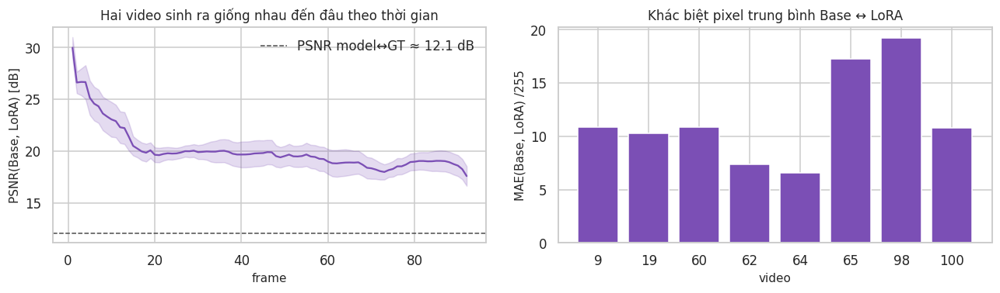

In [48]:
#@title Table 8 · How much does LoRA change the output vs Base?
# per video: PSNR(Base,LoRA), MAE, latent distance
rows = []
for n in NAMES:
    bl = EXT["bl"][n]
    r_ = {"video": n[:-4], "PSNR(Base,LoRA) dB": float(np.mean(bl["psnr_frame"])), "MAE(Base,LoRA) /255": bl["mae"]}
    if n in EXT.get("bl_latent", {}): r_["Latent RMSE(Base,LoRA)"] = EXT["bl_latent"][n]
    rows.append(r_)
T8 = pd.DataFrame(rows).set_index("video"); T8.loc["Trung bình"] = T8.mean()
show_table(T8, "table8_base_vs_lora", "Bảng 8 · Độ khác biệt giữa video Base và video LoRA", styler=lambda T: T.style.format("{:.3f}"))

# pb: base-vs-lora PSNR; pg: avg model-vs-GT PSNR
pb = T8.loc["Trung bình", "PSNR(Base,LoRA) dB"]; pg = float(np.mean([ST["psnr"]["base"], ST["psnr"]["lora"]]))
L = ["#### 📝 Đánh giá Bảng 8 — LoRA đã thay đổi đầu ra bao nhiêu?",
     f"- PSNR giữa video Base và video LoRA (cùng frame đầu, cùng prompt) trung bình **{pb:.1f} dB**, MAE trung bình {T8.loc['Trung bình', 'MAE(Base,LoRA) /255']:.1f}/255. "
     f"Để so sánh, PSNR của mỗi model so với ground-truth chỉ khoảng **{pg:.1f} dB**."]
L.append("- " + ("Hai video Base/LoRA giống nhau *hơn nhiều* so với việc mỗi video giống GT → LoRA chỉ chỉnh nhẹ đầu ra; khoảng cách tới GT chủ yếu do giới hạn của cả mô hình (chuyển động robot, chi tiết vật thể, lệch thời gian/tốc độ khung hình), nên metric khó nhúc nhích." if pb > pg + 3
                else "Hai video Base/LoRA khác nhau ở mức tương đương khoảng cách tới GT → LoRA thực sự thay đổi nội dung sinh ra, nhưng thay đổi đó không làm sát GT hơn (xem Bảng 3)."))
if "Latent RMSE(Base,LoRA)" in T8:
    lg = float(np.mean([ST["latent_l2"]["base"], ST["latent_l2"]["lora"]])) if "latent_l2" in ST else float("nan")
    L.append(f"- Trong không gian latent: khoảng cách Base↔LoRA = {T8.loc['Trung bình', 'Latent RMSE(Base,LoRA)']:.3f}" + (f", so với khoảng cách tới GT ≈ {lg:.3f}." if lg == lg else "."))
# video LoRA changes the most
vmax = T8.iloc[:-1]["PSNR(Base,LoRA) dB"].idxmin()
L.append(f"- Video mà LoRA làm đầu ra thay đổi nhiều nhất là `{vmax}` (PSNR Base↔LoRA = {T8.loc[vmax, 'PSNR(Base,LoRA) dB']:.1f} dB).")
say("\n".join(L))

# left: similarity over time, right: mean pixel diff per video
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
curves = np.stack([EXT["bl"][n]["psnr_frame"] for n in NAMES]); x = np.arange(1, curves.shape[1] + 1)
ax[0].plot(x, curves.mean(0), color="#7b4fb5"); ax[0].fill_between(x, curves.mean(0) - curves.std(0) / np.sqrt(len(NAMES)), curves.mean(0) + curves.std(0) / np.sqrt(len(NAMES)), color="#7b4fb5", alpha=.2)
ax[0].axhline(pg, color=COL["gt"], ls="--", lw=1, label=f"PSNR model↔GT ≈ {pg:.1f} dB"); ax[0].set_xlabel("frame"); ax[0].set_ylabel("PSNR(Base, LoRA) [dB]"); ax[0].set_title("Hai video sinh ra giống nhau đến đâu theo thời gian"); ax[0].legend()
ax[1].bar(VID, T8.iloc[:-1]["MAE(Base,LoRA) /255"], color="#7b4fb5"); ax[1].set_xlabel("video"); ax[1].set_ylabel("MAE(Base, LoRA) /255"); ax[1].set_title("Khác biệt pixel trung bình Base ↔ LoRA")
show_fig(fig, "fig_base_vs_lora_difference.png", "Hình · Mức khác biệt Base ↔ LoRA")

## 11 · Figures

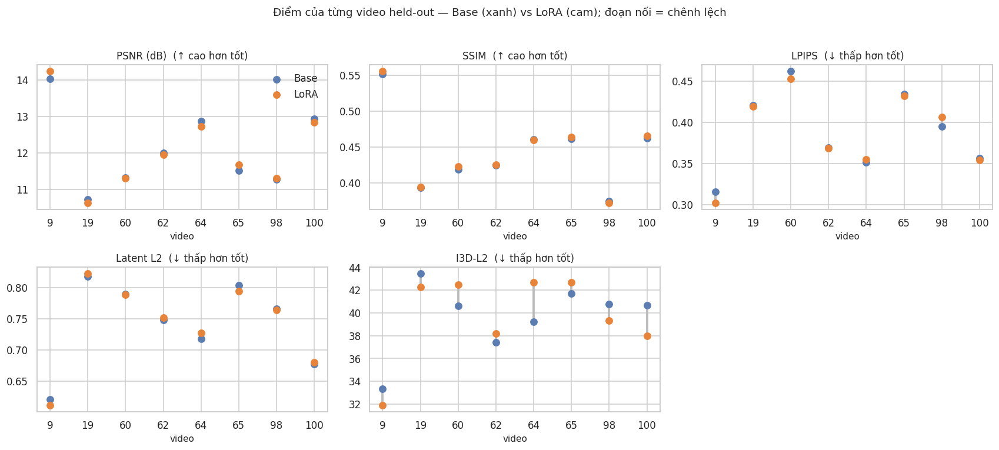

#### 📝 Đánh giá Hình 1
- **PSNR (dB)**: giá trị giữa các video trải trong khoảng 3.31 (Base), trong khi chênh lệch Base↔LoRA ở từng video chỉ cỡ 0.1 (trung bình tuyệt đối) = 3.0% độ trải đó.
- **SSIM**: giá trị giữa các video trải trong khoảng 0.1775 (Base), trong khi chênh lệch Base↔LoRA ở từng video chỉ cỡ 0.00224 (trung bình tuyệt đối) = 1.3% độ trải đó.
- **LPIPS**: giá trị giữa các video trải trong khoảng 0.1465 (Base), trong khi chênh lệch Base↔LoRA ở từng video chỉ cỡ 0.00548 (trung bình tuyệt đối) = 3.7% độ trải đó.
- **Latent L2**: giá trị giữa các video trải trong khoảng 0.1978 (Base), trong khi chênh lệch Base↔LoRA ở từng video chỉ cỡ 0.00511 (trung bình tuyệt đối) = 2.6% độ trải đó.
- **I3D-L2**: giá trị giữa các video trải trong khoảng 10.12 (Base), trong khi chênh lệch Base↔LoRA ở từng video chỉ cỡ 1.73 (trung bình tuyệt đối) = 17.1% độ trải đó.
- **Cách đọc**: hai chấm gần nhau (đoạn nối ngắn) = LoRA gần như không đổi so với Base ở video đó. Thứ tự các video (video nào cao/thấp) gần như giống hệt giữa hai model → *nội dung video* quyết định điểm, không phải model.

In [49]:
#@title Fig 1 · Per-video Base vs LoRA (dumbbell), all metrics
# grid of axes, one per metric
def _grid(k, ncol=3, h=3.4):
    nrow = math.ceil(k / ncol); fig, axs = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, h * nrow)); axs = np.atleast_1d(axs).ravel()
    for a in axs[k:]: a.axis("off")
    return fig, axs
# blue = Base, orange = LoRA
fig, axs = _grid(len(ACTIVE)); x = np.arange(len(NAMES))
for ax, m in zip(axs, ACTIVE):
    lab, hb, f = METRICS[m]; b, l = W[f"{m}_base"].values, W[f"{m}_lora"].values
    for i in x: ax.plot([i, i], [b[i], l[i]], color="#bbbbbb", lw=2.5, zorder=1)
    ax.scatter(x, b, s=55, color=COL["base"], label="Base", zorder=2); ax.scatter(x, l, s=55, color=COL["lora"], label="LoRA", zorder=3)
    ax.set_xticks(x); ax.set_xticklabels(VID); ax.set_xlabel("video"); ax.set_title(f"{lab}  ({'↑ cao hơn tốt' if hb else '↓ thấp hơn tốt'})")
axs[0].legend(loc="best")
fig.suptitle("Điểm của từng video held-out — Base (xanh) vs LoRA (cam); đoạn nối = chênh lệch", y=1.02, fontsize=12)
show_fig(fig, "fig1_per_video_dumbbell.png", "Hình 1 · Từng video, Base vs LoRA")
L = ["#### 📝 Đánh giá Hình 1"]
for m in ACTIVE:
    lab, hb, f = METRICS[m]; b = W[f"{m}_base"]; rng_ = b.max() - b.min()
    L.append(f"- **{lab}**: giá trị giữa các video trải trong khoảng {rng_:.4g} (Base), trong khi chênh lệch Base↔LoRA ở từng video chỉ cỡ {IMP[m].abs().mean():.3g} (trung bình tuyệt đối) = {100 * IMP[m].abs().mean() / rng_:.1f}% độ trải đó.")
L.append("- **Cách đọc**: hai chấm gần nhau (đoạn nối ngắn) = LoRA gần như không đổi so với Base ở video đó. Thứ tự các video (video nào cao/thấp) gần như giống hệt giữa hai model → *nội dung video* quyết định điểm, không phải model.")
say("\n".join(L))

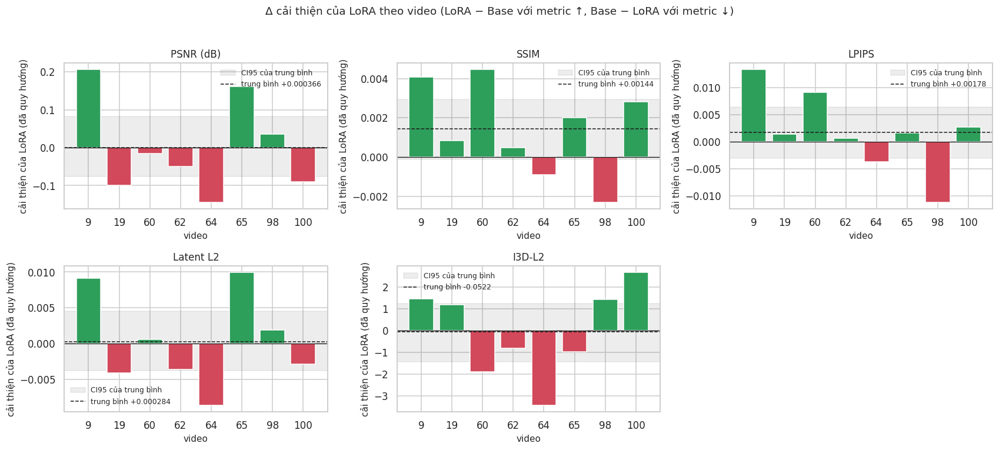

#### 📝 Đánh giá Hình 2
- **PSNR (dB)**: 3 cột xanh / 5 cột đỏ; trung bình +0.000366. Video LoRA giúp nhiều nhất `9` (+0.206), thiệt nhất `64` (-0.144). Dải xám (CI95) chứa 0 → không kết luận được LoRA tốt hơn.
- **SSIM**: 6 cột xanh / 2 cột đỏ; trung bình +0.00144. Video LoRA giúp nhiều nhất `60` (+0.00447), thiệt nhất `98` (-0.0023). Dải xám (CI95) chứa 0 → không kết luận được LoRA tốt hơn.
- **LPIPS**: 6 cột xanh / 2 cột đỏ; trung bình +0.00178. Video LoRA giúp nhiều nhất `9` (+0.0134), thiệt nhất `98` (-0.0112). Dải xám (CI95) chứa 0 → không kết luận được LoRA tốt hơn.
- **Latent L2**: 4 cột xanh / 4 cột đỏ; trung bình +0.000284. Video LoRA giúp nhiều nhất `65` (+0.00994), thiệt nhất `64` (-0.00865). Dải xám (CI95) chứa 0 → không kết luận được LoRA tốt hơn.
- **I3D-L2**: 4 cột xanh / 4 cột đỏ; trung bình -0.0522. Video LoRA giúp nhiều nhất `100` (+2.66), thiệt nhất `64` (-3.43). Dải xám (CI95) chứa 0 → không kết luận được LoRA tốt hơn.
- **Cách đọc**: cột xanh và đỏ xen kẽ với biên độ gần như ngang nhau nghĩa là LoRA chỉ tạo *nhiễu* quanh 0 chứ không tạo cải thiện hệ thống.

In [50]:
#@title Fig 2 · LoRA improvement per video (positive/green = LoRA better)
# gray band = CI95 of mean improvement
fig, axs = _grid(len(ACTIVE))
for ax, m in zip(axs, ACTIVE):
    lab, hb, f = METRICS[m]; imp = IMP[m].values; st = ST[m]
    ci = (st["lo"], st["hi"]) if hb else (-st["hi"], -st["lo"])
    ax.axhspan(ci[0], ci[1], color="k", alpha=.08, label="CI95 của trung bình"); ax.axhline(0, color="k", lw=.8)
    ax.bar(VID, imp, color=[COL["good"] if v > 0 else COL["bad"] for v in imp]); ax.axhline(imp.mean(), color="k", ls="--", lw=1, label=f"trung bình {imp.mean():+.3g}")
    ax.set_title(lab); ax.set_xlabel("video"); ax.set_ylabel("cải thiện của LoRA (đã quy hướng)"); ax.legend(fontsize=8)
fig.suptitle("Δ cải thiện của LoRA theo video (LoRA − Base với metric ↑, Base − LoRA với metric ↓)", y=1.02, fontsize=12)
show_fig(fig, "fig2_improvement_per_video.png", "Hình 2 · Cải thiện của LoRA theo video")
L = ["#### 📝 Đánh giá Hình 2"]
for m in ACTIVE:
    lab = METRICS[m][0]; imp = IMP[m]; st = ST[m]
    L.append(f"- **{lab}**: {int((imp > 0).sum())} cột xanh / {int((imp < 0).sum())} cột đỏ; trung bình {imp.mean():+.3g}. Video LoRA giúp nhiều nhất `{imp.idxmax()}` ({imp.max():+.3g}), thiệt nhất `{imp.idxmin()}` ({imp.min():+.3g}). "
             + ("Dải xám (CI95) chứa 0 → không kết luận được LoRA tốt hơn." if st["lo"] <= 0 <= st["hi"] else "Dải xám (CI95) không chứa 0 → có xu hướng nhất quán."))
L.append("- **Cách đọc**: cột xanh và đỏ xen kẽ với biên độ gần như ngang nhau nghĩa là LoRA chỉ tạo *nhiễu* quanh 0 chứ không tạo cải thiện hệ thống.")
say("\n".join(L))

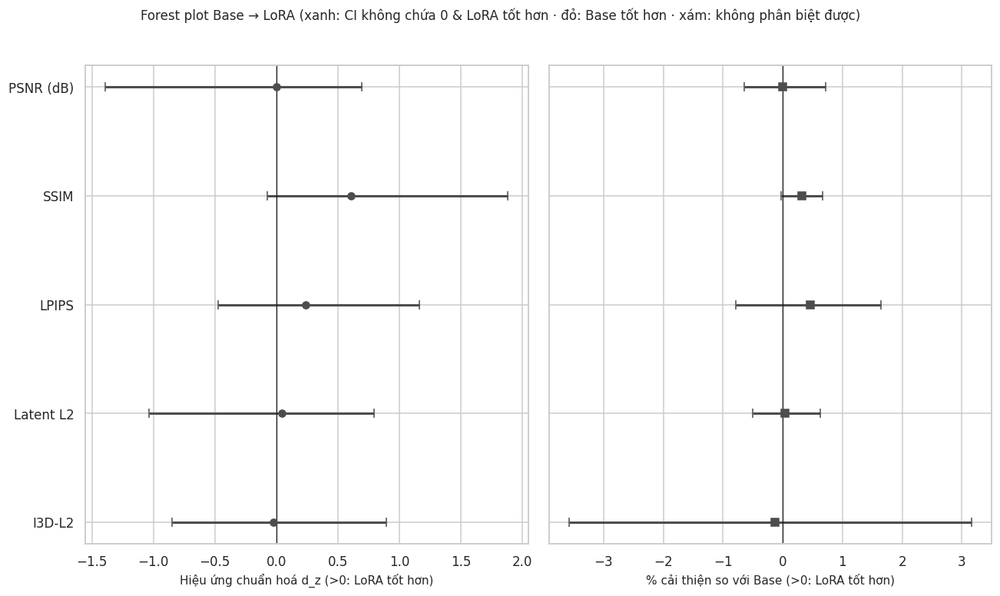

#### 📝 Đánh giá Hình 3
- Hiệu ứng chuẩn hoá lớn nhất là **SSIM** (d_z = +0.61; quy ước ~0.2 nhỏ, 0.5 vừa, 0.8 lớn). Mức thay đổi so với Base chỉ trong khoảng 0.00% – 0.46%.
- Các metric có CI95 (của Δ) chứa 0: PSNR (dB), SSIM, LPIPS, Latent L2, I3D-L2. Tất cả điểm xám đi qua đường 0 → LoRA chưa tạo ra khác biệt có thể đo được.
- Lưu ý: d_z từ 8 mẫu rất không ổn định (CI rộng) — hãy đọc xu hướng chung giữa các metric hơn là con số tuyệt đối.

In [51]:
#@title Fig 3 · Forest plot: effect size (d_z) and % change vs Base, with CI95
rng = np.random.default_rng(1); fig, ax = plt.subplots(1, 2, figsize=(12, 0.9 * len(ACTIVE) + 2.4))
y = np.arange(len(ACTIVE))[::-1]
# bootstrap CI for d_z and % improvement
for k, m in enumerate(ACTIVE):
    imp = IMP[m].values; n = len(imp); idx = rng.integers(0, n, (5000, n)); s = imp[idx]
    sd = s.std(1, ddof=1); dzb = np.where(sd > 0, s.mean(1) / np.where(sd > 0, sd, 1), 0.0)
    lo, hi = np.percentile(dzb, [2.5, 97.5]); dz = ST[m]["dz"]
    rb = 100 * s.mean(1) / abs(W[f"{m}_base"].mean()); rl, rh = np.percentile(rb, [2.5, 97.5]); rm = 100 * imp.mean() / abs(W[f"{m}_base"].mean())
    c = COL["good"] if lo > 0 else COL["bad"] if hi < 0 else COL["gt"]
    ax[0].errorbar(dz, y[k], xerr=[[dz - lo], [hi - dz]], fmt="o", color=c, capsize=4, lw=2); ax[1].errorbar(rm, y[k], xerr=[[rm - rl], [rh - rm]], fmt="s", color=c, capsize=4, lw=2)
for a, t in zip(ax, ("Hiệu ứng chuẩn hoá d_z (>0: LoRA tốt hơn)", "% cải thiện so với Base (>0: LoRA tốt hơn)")):
    a.axvline(0, color="k", lw=.8); a.set_yticks(y); a.set_yticklabels([METRICS[m][0] for m in ACTIVE]); a.set_xlabel(t)
ax[1].set_yticklabels([])
fig.suptitle("Forest plot Base → LoRA (xanh: CI không chứa 0 & LoRA tốt hơn · đỏ: Base tốt hơn · xám: không phân biệt được)", y=1.02, fontsize=11)
show_fig(fig, "fig3_forest_effect_sizes.png", "Hình 3 · Forest plot hiệu ứng")
L = ["#### 📝 Đánh giá Hình 3"]
# biggest effect; metrics whose CI contains 0
big = max(ACTIVE, key=lambda m: abs(ST[m]["dz"])); zero = [METRICS[m][0] for m in ACTIVE if (ST[m]["lo"] <= 0 <= ST[m]["hi"])]
L.append(f"- Hiệu ứng chuẩn hoá lớn nhất là **{METRICS[big][0]}** (d_z = {ST[big]['dz']:+.2f}; quy ước ~0.2 nhỏ, 0.5 vừa, 0.8 lớn). Mức thay đổi so với Base chỉ trong khoảng {min(abs(ST[m]['rel']) for m in ACTIVE):.2f}% – {max(abs(ST[m]['rel']) for m in ACTIVE):.2f}%.")
L.append(f"- Các metric có CI95 (của Δ) chứa 0: {', '.join(zero) if zero else 'không có'}. " + ("Tất cả điểm xám đi qua đường 0 → LoRA chưa tạo ra khác biệt có thể đo được." if len(zero) == len(ACTIVE) else "Điểm nào lệch hẳn khỏi 0 là metric mà LoRA có tác động đo được (xanh) hoặc gây hại (đỏ)."))
L.append("- Lưu ý: d_z từ 8 mẫu rất không ổn định (CI rộng) — hãy đọc xu hướng chung giữa các metric hơn là con số tuyệt đối.")
say("\n".join(L))

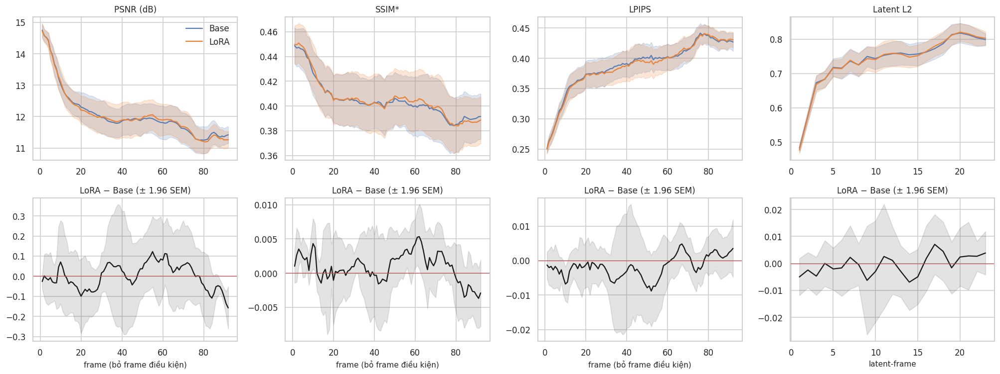

#### 📝 Đánh giá Hình 4
- **PSNR (dB)**: đường LoRA và Base gần như chồng khít; LoRA tốt hơn Base ở 50% số mốc thời gian, |LoRA−Base| lớn nhất là 0.157. Cả hai đều xấu đi theo thời gian (từ 14.5 ở đầu đến 11.4 ở cuối với Base).
- **SSIM***: đường LoRA và Base gần như chồng khít; LoRA tốt hơn Base ở 70% số mốc thời gian, |LoRA−Base| lớn nhất là 0.00534. Cả hai đều xấu đi theo thời gian (từ 0.447 ở đầu đến 0.39 ở cuối với Base).
- **LPIPS**: đường LoRA và Base gần như chồng khít; LoRA tốt hơn Base ở 73% số mốc thời gian, |LoRA−Base| lớn nhất là 0.00881. Cả hai đều xấu đi theo thời gian (từ 0.271 ở đầu đến 0.428 ở cuối với Base).
- **Latent L2**: đường LoRA và Base gần như chồng khít; LoRA tốt hơn Base ở 52% số mốc thời gian, |LoRA−Base| lớn nhất là 0.00708. Cả hai đều xấu đi theo thời gian (từ 0.627 ở đầu đến 0.809 ở cuối với Base).
- **Cách đọc**: hàng dưới là chênh lệch LoRA − Base; nếu dải đen (±1.96 SEM) luôn chứa đường đỏ y = 0 thì không có thời điểm nào LoRA khác Base một cách đáng tin. Phần lớn sai số tích luỹ theo thời gian là của *cả hai* model, tức giới hạn của mô hình nền chứ không phải do LoRA.

In [52]:
#@title Fig 4 · Time curves (mean of 8 videos ± SEM): Base vs LoRA and difference
# top: Base vs LoRA, bottom: LoRA − Base
keys = list(CURVES); fig, axs = plt.subplots(2, len(keys), figsize=(4.6 * len(keys), 7), squeeze=False)
for j, m in enumerate(keys):
    cb, cl = CURVES[m]["base"], CURVES[m]["lora"]; T = cb.shape[1]; x = np.arange(1, T + 1); sem = lambda a: a.std(0, ddof=1) / np.sqrt(a.shape[0])
    for r, c in (("base", cb), ("lora", cl)):
        axs[0, j].plot(x, c.mean(0), color=COL[r], label=LAB[r]); axs[0, j].fill_between(x, c.mean(0) - sem(c), c.mean(0) + sem(c), color=COL[r], alpha=.2)
    d = cl - cb; axs[1, j].plot(x, d.mean(0), color="k"); axs[1, j].fill_between(x, d.mean(0) - 1.96 * sem(d), d.mean(0) + 1.96 * sem(d), color="k", alpha=.12); axs[1, j].axhline(0, color="r", lw=.8)
    axs[0, j].set_title(CURVE_LAB[m]); axs[1, j].set_title("LoRA − Base (± 1.96 SEM)"); axs[1, j].set_xlabel("latent-frame" if m == "latent_l2" else "frame (bỏ frame điều kiện)")
axs[0, 0].legend()
show_fig(fig, "fig4_time_curves.png", "Hình 4 · Đường cong theo thời gian")
L = ["#### 📝 Đánh giá Hình 4"]
for m in keys:
    cb, cl = CURVES[m]["base"], CURVES[m]["lora"]; d = (cl - cb).mean(0); hb = METRICS[m][1] if m in METRICS else True
    frac = float(((d > 0) if hb else (d < 0)).mean())
    L.append(f"- **{CURVE_LAB[m]}**: đường LoRA và Base gần như chồng khít; LoRA tốt hơn Base ở {frac:.0%} số mốc thời gian, |LoRA−Base| lớn nhất là {np.abs(d).max():.3g}. "
             f"Cả hai đều xấu đi theo thời gian (từ {cb.mean(0)[:5].mean():.3g} ở đầu đến {cb.mean(0)[-5:].mean():.3g} ở cuối với Base).")
L.append("- **Cách đọc**: hàng dưới là chênh lệch LoRA − Base; nếu dải đen (±1.96 SEM) luôn chứa đường đỏ y = 0 thì không có thời điểm nào LoRA khác Base một cách đáng tin. "
         "Phần lớn sai số tích luỹ theo thời gian là của *cả hai* model, tức giới hạn của mô hình nền chứ không phải do LoRA.")
say("\n".join(L))

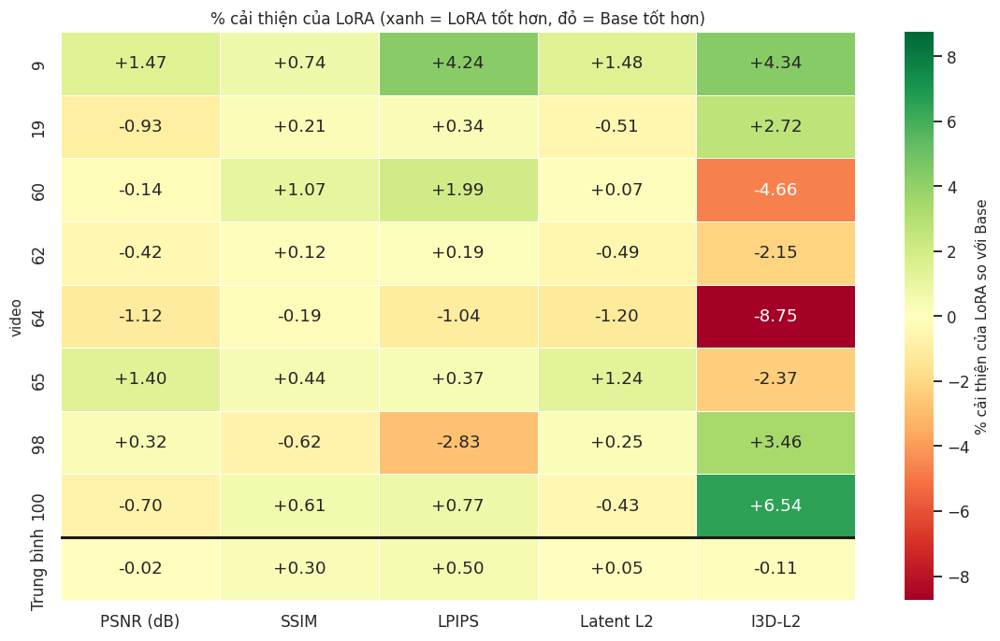

#### 📝 Đánh giá Hình 5
- Ô có thay đổi lớn nhất: video `64` ở **I3D-L2** (-8.75%). Toàn bảng chỉ dao động trong ±8.75%.
- Hàng 'Trung bình' (dưới đường đen): PSNR (dB) -0.02%, SSIM +0.30%, LPIPS +0.50%, Latent L2 +0.05%, I3D-L2 -0.11%.
- **Cách đọc**: nếu một *hàng* (video) xanh đồng loạt thì LoRA giúp nhất quán video đó; nếu một *cột* (metric) xanh đồng loạt thì LoRA cải thiện metric đó. Mảng màu loang lổ xanh/đỏ xen kẽ = tác động không nhất quán.

In [53]:
#@title Fig 5 · Heatmap of LoRA % improvement: video × metric
fig, ax = plt.subplots(figsize=(1.6 * len(ACTIVE) + 2.5, 0.55 * len(NAMES) + 2))
# M: % improvement table + mean row
M = REL.copy(); M.columns = [METRICS[m][0] for m in ACTIVE]; M.loc["Trung bình"] = M.mean()
# symmetric color scale around 0
v = max(abs(M.values).max(), 1e-6)
sns.heatmap(M, annot=True, fmt="+.2f", cmap="RdYlGn", center=0, vmin=-v, vmax=v, linewidths=.5, cbar_kws={"label": "% cải thiện của LoRA so với Base"}, ax=ax)
ax.axhline(len(NAMES), color="k", lw=2); ax.set_ylabel("video"); ax.set_title("% cải thiện của LoRA (xanh = LoRA tốt hơn, đỏ = Base tốt hơn)")
show_fig(fig, "fig5_improvement_heatmap.png", "Hình 5 · Heatmap % cải thiện")
# biggest change
cmax = M.iloc[:-1].abs().stack().idxmax(); mx = M.iloc[:-1].abs().max().max()
L = ["#### 📝 Đánh giá Hình 5",
     f"- Ô có thay đổi lớn nhất: video `{cmax[0]}` ở **{cmax[1]}** ({M.loc[cmax[0], cmax[1]]:+.2f}%). Toàn bảng chỉ dao động trong ±{mx:.2f}%.",
     f"- Hàng 'Trung bình' (dưới đường đen): " + ", ".join(f"{c} {M.loc['Trung bình', c]:+.2f}%" for c in M.columns) + ".",
     "- **Cách đọc**: nếu một *hàng* (video) xanh đồng loạt thì LoRA giúp nhất quán video đó; nếu một *cột* (metric) xanh đồng loạt thì LoRA cải thiện metric đó. Mảng màu loang lổ xanh/đỏ xen kẽ = tác động không nhất quán."]
say("\n".join(L))

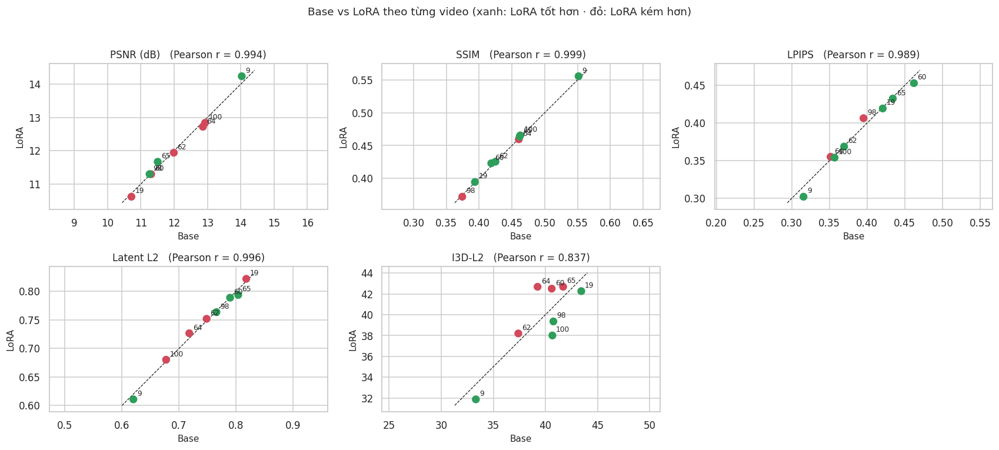

#### 📝 Đánh giá Hình 6
- **PSNR (dB)**: tương quan Base–LoRA r = 0.994; các điểm nằm sát đường chéo → LoRA giữ nguyên thứ hạng độ khó giữa các video.
- **SSIM**: tương quan Base–LoRA r = 0.999; các điểm nằm sát đường chéo → LoRA giữ nguyên thứ hạng độ khó giữa các video.
- **LPIPS**: tương quan Base–LoRA r = 0.989; các điểm nằm sát đường chéo → LoRA giữ nguyên thứ hạng độ khó giữa các video.
- **Latent L2**: tương quan Base–LoRA r = 0.996; các điểm nằm sát đường chéo → LoRA giữ nguyên thứ hạng độ khó giữa các video.
- **I3D-L2**: tương quan Base–LoRA r = 0.837; các điểm lệch khỏi đường chéo đáng kể → LoRA đổi thứ hạng một số video.
- **Cách đọc**: khoảng cách dọc từ điểm tới đường chéo = mức thay đổi do LoRA. Điểm xanh phía tốt, đỏ phía xấu; điểm càng xa đường chéo càng chịu tác động nhiều.

In [54]:
#@title Fig 6 · Base (x) vs LoRA (y) per video; on the diagonal = no change
# green = LoRA better, red = worse, gray = same
fig, axs = _grid(len(ACTIVE))
for ax, m in zip(axs, ACTIVE):
    lab, hb, f = METRICS[m]; b, l = W[f"{m}_base"].values, W[f"{m}_lora"].values
    lo_, hi_ = min(b.min(), l.min()), max(b.max(), l.max()); pad = .05 * (hi_ - lo_ + 1e-9)
    ax.plot([lo_ - pad, hi_ + pad], [lo_ - pad, hi_ + pad], color="k", lw=.8, ls="--")
    ax.scatter(b, l, s=60, color=[COL["good"] if ((li > bi) == hb and li != bi) else COL["bad"] if li != bi else COL["gt"] for bi, li in zip(b, l)], zorder=3)
    for bi, li, v_ in zip(b, l, VID): ax.annotate(v_, (bi, li), textcoords="offset points", xytext=(4, 4), fontsize=8)
    r_ = np.corrcoef(b, l)[0, 1]; ax.set_title(f"{lab}   (Pearson r = {r_:.3f})"); ax.set_xlabel("Base"); ax.set_ylabel("LoRA"); ax.set_aspect("equal", adjustable="datalim")
fig.suptitle("Base vs LoRA theo từng video (xanh: LoRA tốt hơn · đỏ: LoRA kém hơn)", y=1.02, fontsize=12)
show_fig(fig, "fig6_base_vs_lora_scatter.png", "Hình 6 · Scatter Base vs LoRA")
L = ["#### 📝 Đánh giá Hình 6"]
for m in ACTIVE:
    r_ = np.corrcoef(W[f"{m}_base"], W[f"{m}_lora"])[0, 1]; L.append(f"- **{METRICS[m][0]}**: tương quan Base–LoRA r = {r_:.3f}; " + ("các điểm nằm sát đường chéo → LoRA giữ nguyên thứ hạng độ khó giữa các video." if r_ > 0.95 else "các điểm lệch khỏi đường chéo đáng kể → LoRA đổi thứ hạng một số video."))
L.append("- **Cách đọc**: khoảng cách dọc từ điểm tới đường chéo = mức thay đổi do LoRA. Điểm xanh phía tốt, đỏ phía xấu; điểm càng xa đường chéo càng chịu tác động nhiều.")
say("\n".join(L))

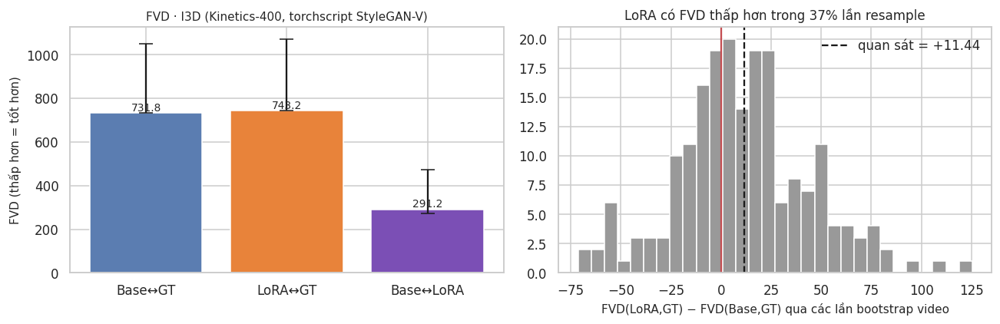

#### 📝 Đánh giá Hình 7
- Cột Base↔GT = 731.8, LoRA↔GT = 743.2; thanh sai số là CI95 bootstrap theo video — hai thanh chồng lấn mạnh.
- Histogram bên phải là phân phối của FVD(LoRA) − FVD(Base): CI95 = [-54.8, +78.3] → chứa 0 → chưa đủ bằng chứng LoRA khác Base về FVD.
- Cột tím (Base↔LoRA) = 291.2 cho biết hai model sinh ra phân phối khác nhau bao nhiêu; nếu nhỏ hơn nhiều hai cột còn lại thì LoRA chưa dịch chuyển đầu ra nhiều.
- FVD ở đây dựa trên rất ít video nên chỉ mang tính so sánh tương đối (xem lưu ý ở Bảng 4).

In [55]:
#@title Fig 7 · FVD: GT vs Base, GT vs LoRA (bootstrap CI95) and difference distribution
# skip if FVD wasn't computed
if FVD is None:
    print("⚠️ Chưa có FVD (cell 9e / Bảng 4 chưa chạy được) → bỏ qua Hình 7")
else:
    pt, bs, db = FVD["point"], FVD["boot"], FVD["dboot"]
    # left: FVD bars, right: hist of FVD(LoRA) − FVD(Base)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ks = ["base", "lora", "base↔lora"]; cs = [COL["base"], COL["lora"], "#7b4fb5"]
    ax[0].bar(["Base↔GT", "LoRA↔GT", "Base↔LoRA"], [pt[k] for k in ks], color=cs, yerr=[[max(pt[k] - np.percentile(bs[k], 2.5), 0) for k in ks], [max(np.percentile(bs[k], 97.5) - pt[k], 0) for k in ks]], capsize=6)
    for i, k in enumerate(ks): ax[0].text(i, pt[k], f"{pt[k]:.1f}", ha="center", va="bottom", fontsize=9)
    ax[0].set_ylabel("FVD (thấp hơn = tốt hơn)"); ax[0].set_title(f"FVD · {FVD['backbone']}", fontsize=10)
    ax[1].hist(db, bins=30, color="#999999"); ax[1].axvline(0, color="r"); ax[1].axvline(pt["lora"] - pt["base"], color="k", ls="--", label=f"quan sát = {pt['lora'] - pt['base']:+.2f}")
    ax[1].set_xlabel("FVD(LoRA,GT) − FVD(Base,GT) qua các lần bootstrap video"); ax[1].set_title(f"LoRA có FVD thấp hơn trong {float((db < 0).mean()):.0%} lần resample"); ax[1].legend()
    show_fig(fig, "fig7_fvd.png", "Hình 7 · FVD")
    lo, hi = np.percentile(db, [2.5, 97.5])
    say("#### 📝 Đánh giá Hình 7\n"
        f"- Cột Base↔GT = {pt['base']:.1f}, LoRA↔GT = {pt['lora']:.1f}; thanh sai số là CI95 bootstrap theo video — {'hai thanh chồng lấn mạnh' if abs(pt['lora'] - pt['base']) < (np.percentile(bs['base'], 97.5) - np.percentile(bs['base'], 2.5)) / 2 else 'hai thanh khá tách nhau'}.\n"
        f"- Histogram bên phải là phân phối của FVD(LoRA) − FVD(Base): CI95 = [{lo:+.1f}, {hi:+.1f}] → " + ("không chứa 0, LoRA khác Base về FVD." if (lo > 0 or hi < 0) else "chứa 0 → chưa đủ bằng chứng LoRA khác Base về FVD.") + "\n"
        f"- Cột tím (Base↔LoRA) = {pt['base↔lora']:.1f} cho biết hai model sinh ra phân phối khác nhau bao nhiêu; nếu nhỏ hơn nhiều hai cột còn lại thì LoRA chưa dịch chuyển đầu ra nhiều.\n"
        "- FVD ở đây dựa trên rất ít video nên chỉ mang tính so sánh tương đối (xem lưu ý ở Bảng 4).")

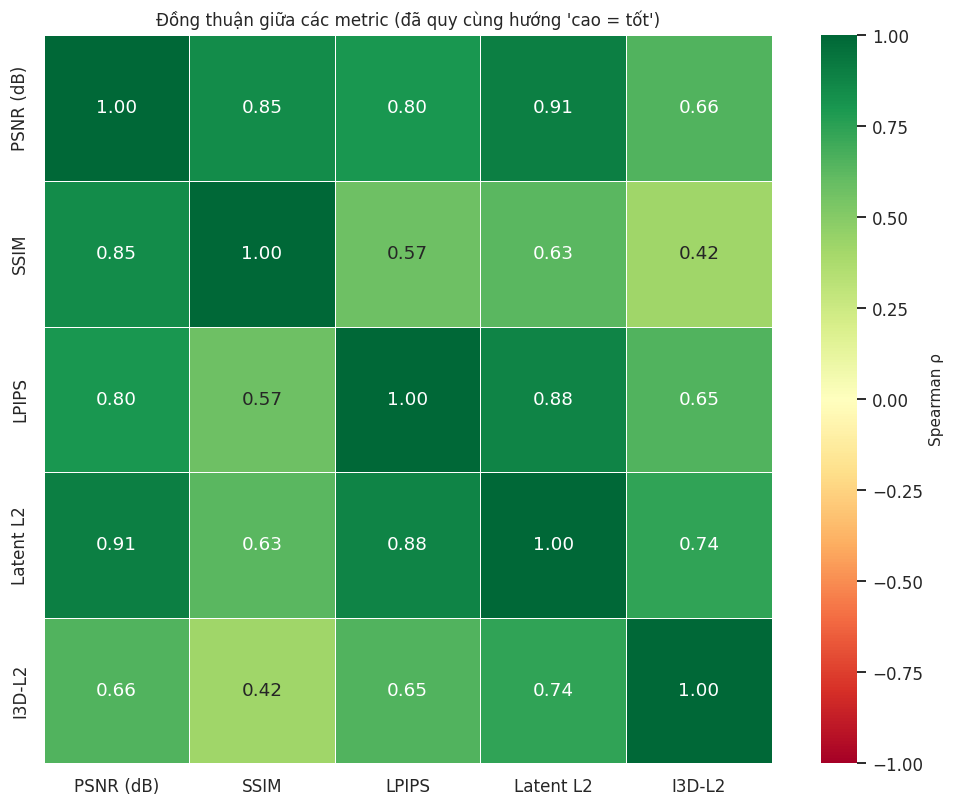

#### 📝 Đánh giá Hình 8
- Tương quan Spearman ngoài đường chéo nằm trong khoảng [+0.42, +0.91], trung bình +0.71.
- Ô xanh đậm = hai metric xếp hạng các (video, model) giống nhau; ô đỏ/nhạt = hai metric bất đồng, tức chúng đang bắt các khía cạnh chất lượng khác nhau. Vì vậy kết luận về LoRA nên dựa trên *nhiều* metric cùng lúc (Bảng 3, 6 và Hình 3) thay vì chỉ PSNR/SSIM.

In [56]:
#@title Fig 8 · Metric correlation heatmap
# reuses T7 from table 7
fig, ax = plt.subplots(figsize=(1.3 * len(ACTIVE) + 3, 1.1 * len(ACTIVE) + 2))
sns.heatmap(T7, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1, linewidths=.5, square=True, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Đồng thuận giữa các metric (đã quy cùng hướng 'cao = tốt')")
show_fig(fig, "fig8_metric_correlation.png", "Hình 8 · Tương quan metric")
# off-diagonal correlations
off = T7.values[~np.eye(len(T7), dtype=bool)]
say("#### 📝 Đánh giá Hình 8\n"
    f"- Tương quan Spearman ngoài đường chéo nằm trong khoảng [{off.min():+.2f}, {off.max():+.2f}], trung bình {off.mean():+.2f}.\n"
    "- Ô xanh đậm = hai metric xếp hạng các (video, model) giống nhau; ô đỏ/nhạt = hai metric bất đồng, tức chúng đang bắt các khía cạnh chất lượng khác nhau. "
    "Vì vậy kết luận về LoRA nên dựa trên *nhiều* metric cùng lúc (Bảng 3, 6 và Hình 3) thay vì chỉ PSNR/SSIM.")

## 12 · Visual comparison of all 8 videos

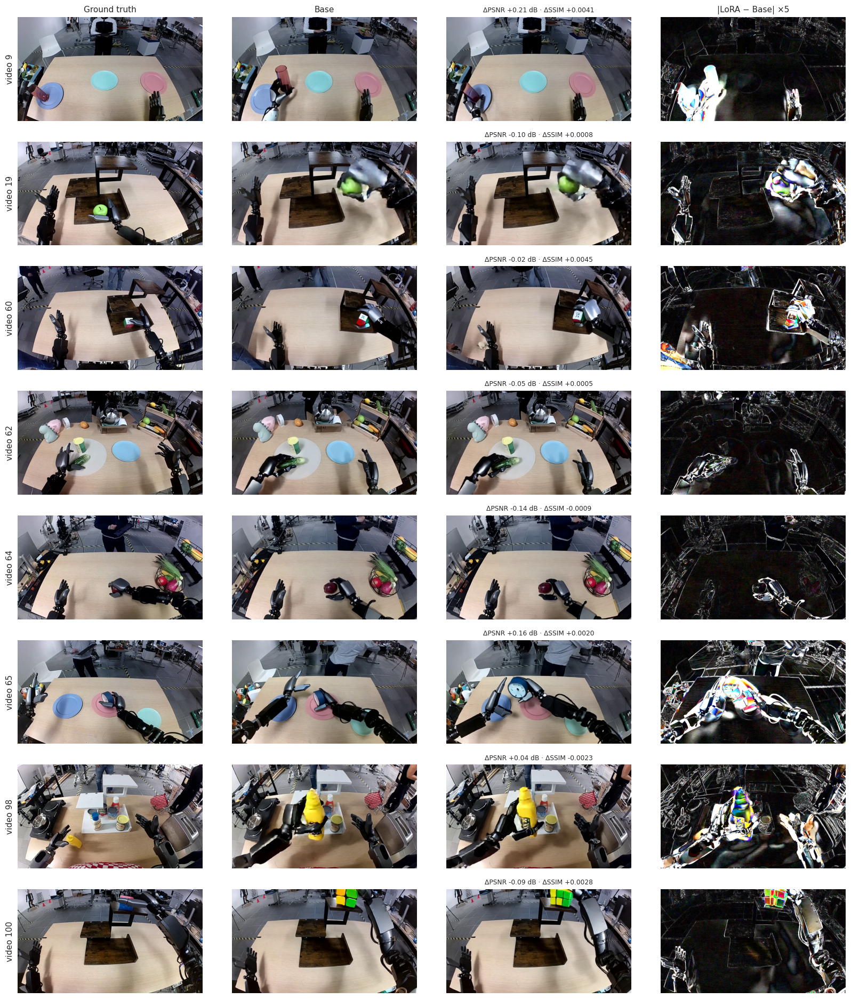

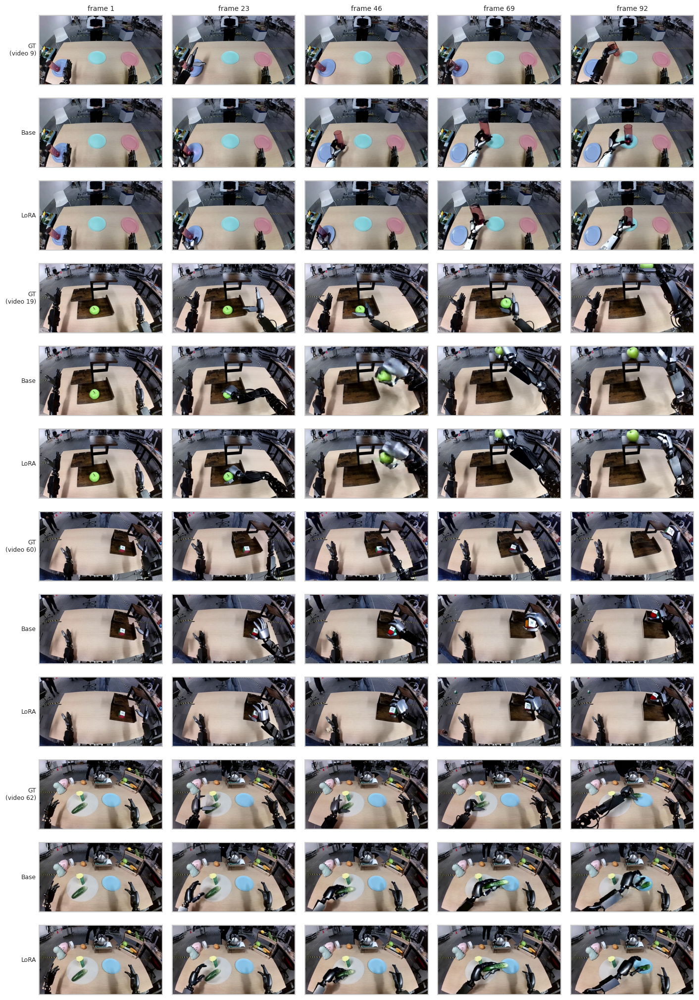

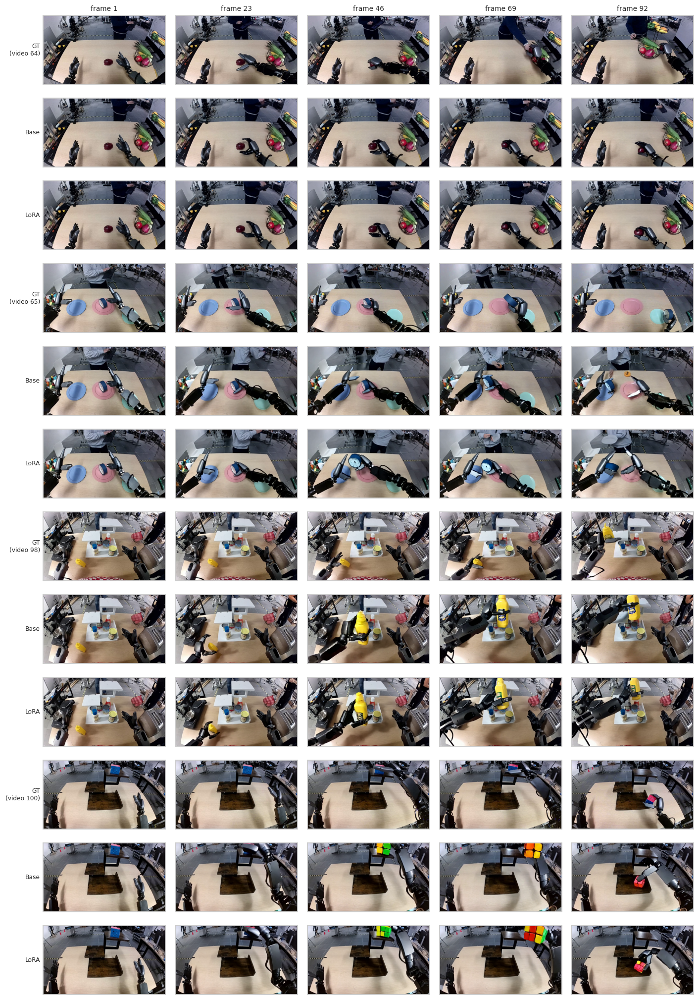

#### 📝 Đánh giá Hình 9–10
- Cột thứ 4 là hiệu tuyệt đối |LoRA − Base| khuếch đại ×5: vùng sáng là nơi LoRA thực sự vẽ khác Base. Trung bình chênh lệch pixel Base↔LoRA chỉ 11.7/255 (Bảng 8).
- ΔPSNR theo video dao động từ -0.14 dB (video `64`) đến +0.21 dB (video `9`).
- Quan sát bằng mắt nên tập trung vào: (1) cánh tay/bàn tay robot có đi đúng quỹ đạo như GT không, (2) vật thể bị gắp có giữ đúng hình dạng/màu không, (3) hậu cảnh có bị 'trôi' dần về cuối clip không. Ở các hàng của Hình 10, so sánh cột frame 92 (cuối clip) giữa GT, Base và LoRA — đây là chỗ sai khác tích luỹ rõ nhất.
- Lưu ý: GT gốc là 20 fps còn video sinh ra là 16 fps nhưng code gốc (và các metric ở đây) căn theo *chỉ số frame*, nên cùng một chỉ số frame có thể tương ứng hai thời điểm hơi khác nhau; điều này làm giảm PSNR/SSIM tuyệt đối của cả Base lẫn LoRA như nhau.

In [57]:
#@title Fig 9 · All 8 videos: GT | Base | LoRA | |LoRA − Base| (×5) at mid clip
# figs 9-10
FR = 46  # mid frame (0..92)
# 8 rows × 4 cols
fig, ax = plt.subplots(len(NAMES), 4, figsize=(15, 2.15 * len(NAMES)))
for i, n in enumerate(NAMES):
    gt, b, l = load_aligned(n); d = np.clip(np.abs(l[FR].astype(np.int16) - b[FR].astype(np.int16)) * 5, 0, 255).astype(np.uint8)
    for j, (img, t) in enumerate(((gt[FR], "Ground truth"), (b[FR], "Base"), (l[FR], "LoRA"), (d, "|LoRA − Base| ×5"))):
        ax[i, j].imshow(img); ax[i, j].axis("off")
        if i == 0: ax[i, j].set_title(t, fontsize=10)
    ax[i, 0].text(-0.02, 0.5, f"video {n[:-4]}", transform=ax[i, 0].transAxes, rotation=90, va="center", ha="right", fontsize=10)
    ax[i, 2].set_title(f"ΔPSNR {SC['lora'][n]['psnr'] - SC['base'][n]['psnr']:+.2f} dB · ΔSSIM {SC['lora'][n]['ssim'] - SC['base'][n]['ssim']:+.4f}", fontsize=8)
show_fig(fig, "fig9_qualitative_all8.png", "Hình 9 · So sánh trực quan 8 video")

# strips: frames 1, 23, 46, 69, 92
def strips(names, fname, title):
    ts = [1, 23, 46, 69, 92]; fig, ax = plt.subplots(3 * len(names), len(ts), figsize=(2.6 * len(ts), 1.55 * 3 * len(names)))
    for i, n in enumerate(names):
        gt, b, l = load_aligned(n)
        for r, (lab, v) in enumerate((("GT", gt), ("Base", b), ("LoRA", l))):
            for c, t in enumerate(ts):
                a = ax[3 * i + r, c]; a.imshow(v[t]); a.set_xticks([]); a.set_yticks([])
                if i == 0 and r == 0: a.set_title(f"frame {t}", fontsize=9)
            ax[3 * i + r, 0].set_ylabel(f"{lab}" + (f"\n(video {n[:-4]})" if r == 0 else ""), fontsize=8, rotation=0, ha="right", va="center")
    show_fig(fig, fname, title)
strips(NAMES[:4], "fig10a_strips_videos_1-4.png", "Hình 10a · Diễn tiến theo thời gian (video 1-4)")
strips(NAMES[4:], "fig10b_strips_videos_5-8.png", "Hình 10b · Diễn tiến theo thời gian (video 5-8)")
# dd: per-video PSNR gain
dd = {n: SC["lora"][n]["psnr"] - SC["base"][n]["psnr"] for n in NAMES}
say("#### 📝 Đánh giá Hình 9–10\n"
    f"- Cột thứ 4 là hiệu tuyệt đối |LoRA − Base| khuếch đại ×5: vùng sáng là nơi LoRA thực sự vẽ khác Base. Trung bình chênh lệch pixel Base↔LoRA chỉ {np.mean([EXT['bl'][n]['mae'] for n in NAMES]):.1f}/255 (Bảng 8).\n"
    f"- ΔPSNR theo video dao động từ {min(dd.values()):+.2f} dB (video `{min(dd, key=dd.get)[:-4]}`) đến {max(dd.values()):+.2f} dB (video `{max(dd, key=dd.get)[:-4]}`).\n"
    "- Quan sát bằng mắt nên tập trung vào: (1) cánh tay/bàn tay robot có đi đúng quỹ đạo như GT không, (2) vật thể bị gắp có giữ đúng hình dạng/màu không, (3) hậu cảnh có bị 'trôi' dần về cuối clip không. "
    "Ở các hàng của Hình 10, so sánh cột frame 92 (cuối clip) giữa GT, Base và LoRA — đây là chỗ sai khác tích luỹ rõ nhất.\n"
    "- Lưu ý: GT gốc là 20 fps còn video sinh ra là 16 fps nhưng code gốc (và các metric ở đây) căn theo *chỉ số frame*, nên cùng một chỉ số frame có thể tương ứng hai thời điểm hơi khác nhau; điều này làm giảm PSNR/SSIM tuyệt đối của cả Base lẫn LoRA như nhau.")

In [58]:
#@title Compare videos GT | Base | LoRA for all 8 videos
import imageio_ffmpeg, IPython.display as ipd
FF = imageio_ffmpeg.get_ffmpeg_exe()
# make side-by-side, then a light copy for embedding
for n in NAMES:
    out = RES / f"compare_{n}"
    if not out.exists():
        vm.side_by_side([GT / n, ROOT / f"output/eval/base/{n}", ROOT / f"output/eval/lora/{n}"], ["ground truth", "base", "LoRA"], out)  # same function as section 8
    small = RES / f"compact_{n}"  # light copy (1152 px wide), embed only
    subprocess.run([FF, "-y", "-loglevel", "error", "-i", str(out), "-vf", "scale=1152:-2", "-c:v", "libx264", "-crf", "30", "-preset", "veryfast", "-pix_fmt", "yuv420p", "-an", str(small)], check=True)
    display(Markdown(f"**video {n[:-4]}** — ΔPSNR {SC['lora'][n]['psnr'] - SC['base'][n]['psnr']:+.2f} dB · ΔSSIM {SC['lora'][n]['ssim'] - SC['base'][n]['ssim']:+.4f}  (trái → phải: ground truth | base | LoRA)"))
    ipd.display(ipd.Video(str(small), embed=True, width=900))
print("Bản đầy đủ của 8 video nằm ở:", RES, "→ compare_<id>.mp4")

**video 9** — ΔPSNR +0.21 dB · ΔSSIM +0.0041  (trái → phải: ground truth | base | LoRA)

**video 19** — ΔPSNR -0.10 dB · ΔSSIM +0.0008  (trái → phải: ground truth | base | LoRA)

**video 60** — ΔPSNR -0.02 dB · ΔSSIM +0.0045  (trái → phải: ground truth | base | LoRA)

**video 62** — ΔPSNR -0.05 dB · ΔSSIM +0.0005  (trái → phải: ground truth | base | LoRA)

**video 64** — ΔPSNR -0.14 dB · ΔSSIM -0.0009  (trái → phải: ground truth | base | LoRA)

**video 65** — ΔPSNR +0.16 dB · ΔSSIM +0.0020  (trái → phải: ground truth | base | LoRA)

**video 98** — ΔPSNR +0.04 dB · ΔSSIM -0.0023  (trái → phải: ground truth | base | LoRA)

**video 100** — ΔPSNR -0.09 dB · ΔSSIM +0.0028  (trái → phải: ground truth | base | LoRA)

Bản đầy đủ của 8 video nằm ở: /content/eyecode-official/results → compare_<id>.mp4


## 13 · Overall conclusion

In [59]:
#@title Overall conclusion (auto-generated from the numbers)
# table 9 + auto conclusion
rows = []
for m in ACTIVE:
    lab, hb, _ = METRICS[m]; st = ST[m]; rows.append({"Metric": lab, "Base": st["base"], "LoRA": st["lora"], "Δ %": st["rel"], "LoRA thắng": f"{st['win']}/{st['n']}", "Kết luận": verdict(st, hb)})
if FVD is not None:
    pt, db = FVD["point"], FVD["dboot"]; lo, hi = np.percentile(db, [2.5, 97.5])
    rows.append({"Metric": "FVD", "Base": pt["base"], "LoRA": pt["lora"], "Δ %": 100 * (pt["lora"] - pt["base"]) / pt["base"], "LoRA thắng": f"{float((db < 0).mean()):.0%} bootstrap",
                 "Kết luận": "LoRA tốt hơn (có ý nghĩa thống kê)" if hi < 0 else "Base tốt hơn (có ý nghĩa thống kê)" if lo > 0 else "không có khác biệt rõ rệt"})
TC = pd.DataFrame(rows).set_index("Metric")
show_table(TC, "table9_overall", "Bảng 9 · Tổng hợp mọi metric", styler=lambda T: T.style.format({"Base": "{:.4f}", "LoRA": "{:.4f}", "Δ %": "{:+.2f}"}))
# counts: significant / LoRA / Base / no difference
ns = int(sum("có ý nghĩa thống kê" in v for v in TC["Kết luận"])); nl = int(sum(v.startswith("LoRA tốt hơn (có ý nghĩa") for v in TC["Kết luận"])); nb = int(sum(v.startswith("Base tốt hơn (có ý nghĩa") for v in TC["Kết luận"]))
nn = int(sum(v == "không có khác biệt rõ rệt" for v in TC["Kết luận"]))
if nl >= max(2, len(TC) // 2) and nb == 0: head = "LoRA **cải thiện rõ rệt** so với Base trên đa số metric."
elif nl >= 1 and nb == 0: head = f"LoRA cải thiện **ở {nl} metric** nhưng chưa đồng đều trên mọi metric."
elif nb >= 1 and nl == 0: head = f"LoRA **không giúp ích** và còn tệ hơn Base ở {nb} metric."
elif ns == 0: head = "**Chưa đo được khác biệt đáng tin cậy** giữa LoRA và Base ở thiết lập này."
else: head = "Kết quả **lẫn lộn**: có metric nghiêng về LoRA, có metric nghiêng về Base."
# mde: CI half-width, for the limitations note
mde = ", ".join(f"{METRICS[m][0]} ±{ST[m]['half']:.3g}" for m in ACTIVE[:3])
say(f"#### 🏁 Kết luận\n\n{head}\n\n"
    f"- Trong {len(TC)} metric: **{nl}** nghiêng hẳn về LoRA (có ý nghĩa), **{nb}** nghiêng hẳn về Base, **{nn}** không có khác biệt rõ rệt, còn lại ở mức xu hướng chưa chắc chắn.\n"
    f"- Thang đo của sai số: PSNR trung bình chỉ ~{ST['psnr']['base']:.1f} dB và SSIM ~{ST['ssim']['base']:.2f} cho cả hai model, nghĩa là cả Base lẫn LoRA đều còn *rất xa* video thật; phần chênh lệch giữa hai model ({ST['psnr']['diff']:+.3f} dB) nhỏ hơn nhiều so với độ lệch giữa các video.\n"
    f"- **Giới hạn của thí nghiệm** (cần nêu khi báo cáo): (1) chỉ 8 video held-out → nửa độ rộng CI cỡ {mde}; (2) LoRA mới huấn luyện 300 iteration trên 24 video nên khó kỳ vọng thay đổi lớn; "
    "(3) PSNR/SSIM so khớp từng pixel rất khắt khe với bài toán sinh video (chỉ cần lệch vài frame chuyển động là điểm tụt mạnh) và GT 20 fps bị căn theo chỉ số frame với video 16 fps; "
    "(4) FVD/Latent L2 dùng backbone ngoài (xem nhãn backbone ở Bảng 4) nên chỉ so sánh tương đối; (5) một seed sinh mỗi video.\n"
    "- **Hướng làm tiếp nếu muốn chênh lệch rõ hơn**: huấn luyện lâu hơn/nhiều video hơn, tăng số video đánh giá (≥ 30), nhiều seed mỗi video, và dùng metric bám sát thao tác robot (vị trí tay/vật thể) bên cạnh metric ảnh.")

,Base,LoRA,Δ %,LoRA thắng,Kết luận
Metric,,,,,
PSNR (dB),12.0772,12.0775,+0.00,3/8,không có khác biệt rõ rệt
SSIM,0.4434,0.4448,+0.32,6/8,không có khác biệt rõ rệt
LPIPS,0.3882,0.3865,-0.46,6/8,không có khác biệt rõ rệt
Latent L2,0.7424,0.7421,-0.04,4/8,không có khác biệt rõ rệt
I3D-L2,39.6409,39.6931,+0.13,4/8,không có khác biệt rõ rệt
FVD,731.7877,743.2240,+1.56,37% bootstrap,không có khác biệt rõ rệt


#### 🏁 Kết luận

**Chưa đo được khác biệt đáng tin cậy** giữa LoRA và Base ở thiết lập này.

- Trong 6 metric: **0** nghiêng hẳn về LoRA (có ý nghĩa), **0** nghiêng hẳn về Base, **6** không có khác biệt rõ rệt, còn lại ở mức xu hướng chưa chắc chắn.
- Thang đo của sai số: PSNR trung bình chỉ ~12.1 dB và SSIM ~0.44 cho cả hai model, nghĩa là cả Base lẫn LoRA đều còn *rất xa* video thật; phần chênh lệch giữa hai model (+0.000 dB) nhỏ hơn nhiều so với độ lệch giữa các video.
- **Giới hạn của thí nghiệm** (cần nêu khi báo cáo): (1) chỉ 8 video held-out → nửa độ rộng CI cỡ PSNR (dB) ±0.105, SSIM ±0.00197, LPIPS ±0.00624; (2) LoRA mới huấn luyện 300 iteration trên 24 video nên khó kỳ vọng thay đổi lớn; (3) PSNR/SSIM so khớp từng pixel rất khắt khe với bài toán sinh video (chỉ cần lệch vài frame chuyển động là điểm tụt mạnh) và GT 20 fps bị căn theo chỉ số frame với video 16 fps; (4) FVD/Latent L2 dùng backbone ngoài (xem nhãn backbone ở Bảng 4) nên chỉ so sánh tương đối; (5) một seed sinh mỗi video.
- **Hướng làm tiếp nếu muốn chênh lệch rõ hơn**: huấn luyện lâu hơn/nhiều video hơn, tăng số video đánh giá (≥ 30), nhiều seed mỗi video, và dùng metric bám sát thao tác robot (vị trí tay/vật thể) bên cạnh metric ảnh.

## 14 · Save results

In [60]:
#@title Save everything (CSV, PNG, report .md, videos) and download
# write report, zip, download
(RES / "report_extended.md").write_text("# Đánh giá mở rộng Base vs LoRA — Cosmos-Predict2\n\n" + "\n\n".join(REPORT), encoding="utf-8")
out_zip = "/content/cosmos_eval_extended.zip"
# zip, skipping compact_ videos
with zipfile.ZipFile(out_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(RES.iterdir()):
        if p.is_file() and not p.name.startswith("compact_") and p.suffix in (".png", ".csv", ".md", ".json", ".mp4", ".pkl"): z.write(p, p.name)
print("Đã lưu:", out_zip, f"({os.path.getsize(out_zip) / 2**20:.0f} MB)")
print(sorted(p.name for p in RES.iterdir() if p.suffix in ('.png', '.csv', '.md')))
# colab only
try:
    from google.colab import files; files.download(out_zip)
except Exception: pass

Đã lưu: /content/cosmos_eval_extended.zip (38 MB)
['fig10a_strips_videos_1-4.png', 'fig10b_strips_videos_5-8.png', 'fig1_per_video_dumbbell.png', 'fig2_improvement_per_video.png', 'fig3_forest_effect_sizes.png', 'fig4_time_curves.png', 'fig5_improvement_heatmap.png', 'fig6_base_vs_lora_scatter.png', 'fig7_fvd.png', 'fig8_metric_correlation.png', 'fig9_qualitative_all8.png', 'fig_base_vs_lora_difference.png', 'qualitative_best_worst.png', 'report_extended.md', 'summary.md', 'table1_per_video.csv', 'table2_summary.csv', 'table3_paired_stats.csv', 'table4_fvd.csv', 'table5_time_segments.csv', 'table6_winloss.csv', 'table7_metric_corr.csv', 'table8_base_vs_lora.csv', 'table9_overall.csv', 'video_metrics_scatter.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>